# Test for Histogram Text Clipping Fix

**Date: 11-04-2026**

**Last Update: 11-08-2026**

## Introduction

- This notebook is a test for developers to test **fix/histogram-text-clipping-spac** functions using results from lymphnode_analysis workbook in "../../paper/example/lymphnode_analysis.ipynb". 
- This notebook tests functions from **templates** only.

### How to use this notebook for testing

- Make a copy of the notebook in your test branch.
- Pull your code into the branch.
- Make sure the kernel is set as the python environment created from environmental.yml
- Write your own testing cells for functions from template.
- Run cells from top to bottom.

### Dataset Overview
We use the final result from the lymphnode_analysis.ipynb, which is stored in "../../data/dev_example.pickle"

Below is the overview of the original dataset
- **Source**: This example uses scimap demo dataset (https://scimap.xyz/tutorials/md/demo_data_scimap/), with additional annotations added for phenotyping analysis named as "example_lymphnode_data.csv". The original data is publicly available normal human lymph node tissue microarray data from CyCIF imaging, preprocessed by MCMICRO. No additional ethical approvals are required for this de-identified published dataset. 
- **Size**: 4,825 cells
- **Markers**: 33 protein markers

## Define Input/Output Paths

In [1]:
# Setup file paths
data_pickle = "../../data/dev_example.pickle"

## Auto-Reload Code Changes

In [2]:
%load_ext autoreload
%autoreload 2

## Understand Data

In [3]:
import pickle

with open(data_pickle, "rb") as f:
    adata = pickle.load(f)

print(f"Object type: {type(adata).__name__}")
print(f"Shape (cells, features): {adata.shape}")
print(f"Original table (X) type: {type(adata.X).__name__}, dtype: {adata.X.dtype}")
print(f"Tables (layers): {list(adata.layers.keys())}")
for name, layer in adata.layers.items():
    print(f"  {name}: shape={layer.shape}, dtype={layer.dtype}")

print(f"\nCell index: dtype={adata.obs.index.dtype}, sample={adata.obs.index[:5].tolist()}")
print("\nAnnotations (adata.obs columns) and data types:")
print(adata.obs.dtypes)
print("\nAnnotations for the first five cells:")
display(adata.obs.head())

print(f"Features ({adata.n_vars}): {adata.var_names.tolist()}")
print(f"Feature index dtype: {adata.var_names.dtype}")
print("\nFeature metadata columns and data types:")
print(adata.var.dtypes)
display(adata.var.head())

Object type: AnnData
Shape (cells, features): (4825, 33)
Original table (X) type: ndarray, dtype: float64
Tables (layers): ['arcsinh_percentile', 'arcsinh_z_scores']
  arcsinh_percentile: shape=(4825, 33), dtype=float64
  arcsinh_z_scores: shape=(4825, 33), dtype=float64

Cell index: dtype=object, sample=['0', '1', '2', '3', '4']

Annotations (adata.obs columns) and data types:
broad_cell_type       category
detailed_cell_type    category
manual_phenotype      category
phenograph_k60_r1     category
renamed_clusters      category
CD3Dspatial_plot       float64
CD20spatial_plot       float64
dtype: object

Annotations for the first five cells:


,broad_cell_type,detailed_cell_type,manual_phenotype,phenograph_k60_r1,renamed_clusters,CD3Dspatial_plot,CD20spatial_plot
0,B Cells,B Cell,"B Cell, CD68+ Macrophage, Dendritic Cell, Prol...",3,Proliferative B cells,-0.996883,1.709721
1,B Cells,Follicular Dendritic Cell,"Follicular Dendritic Cell, Dendritic Cell, Pro...",3,Proliferative B cells,-0.971774,0.582074
2,B Cells,Follicular Dendritic Cell,"Follicular Dendritic Cell, CD68+ Macrophage, D...",3,Proliferative B cells,-0.940262,0.866047
3,B Cells,B Cell,"B Cell, Proliferating Cell, Activated APC",3,Proliferative B cells,-1.481576,1.338160
4,B Cells,Follicular Dendritic Cell,"Follicular Dendritic Cell, Proliferating Cell,...",3,Proliferative B cells,-1.380023,0.666479


Features (33): ['CD25', 'CD2', 'CD10', 'CD163', 'CD3D', 'CD5', 'CD30', 'ACTIN', 'CD45', 'CD206', 'CD68', 'PD1', 'KI67', 'CD11C', 'CD7', 'CD8A', 'FOXP3', 'CD20', 'CD4', 'HLADR', 'PSTAT3', 'PS6', 'PERK', 'CD21', 'CD43', 'NOS2', 'PDL1', 'CD11B', 'CD57', 'MHCI', 'CD15', 'ASMA', 'CD56']
Feature index dtype: object

Feature metadata columns and data types:
Series([], dtype: object)


""
CD25
CD2
CD10
CD163
CD3D


In [4]:
# Copied from notebooks/archived/test_histogram_facet_light.ipynb, cell 13 (zero-based).
# This small loader replaces the helper defined earlier in that notebook.
import pickle

def load_data(file_path):
    with open(file_path, 'rb') as file:
        return pickle.load(file)

# # Load data without verbose output
import io
import contextlib

file_path = data_pickle

# Suppress all output from load_data
with io.StringIO() as buf, contextlib.redirect_stdout(buf):
    preloaded_data = load_data(file_path)

# Get the anndata object
adata = preloaded_data[0] if isinstance(preloaded_data, list) else preloaded_data

print(f"AnnData object created: {adata}")
print(f"Number of cells: {adata.n_obs}")
print(f"Number of features: {adata.n_vars}")
print(f"\nAvailable layers: {list(adata.layers.keys())}")
print(f"Available annotations: {list(adata.obs.columns)}")
print(f"Spatial coordinates: {adata.obsm.keys()}")

AnnData object created: AnnData object with n_obs × n_vars = 4825 × 33
    obs: 'broad_cell_type', 'detailed_cell_type', 'manual_phenotype', 'phenograph_k60_r1', 'renamed_clusters', 'CD3Dspatial_plot', 'CD20spatial_plot'
    uns: 'phenograph_features', 'phenograph_k60_r1_colors', 'renamed_clusters_colors', '_spac_palettes', 'spatial_neighbors', 'renamed_clusters_plot_nhood_enrichment', 'ripley_l_with_edge', 'ripley_l_without_edge', 'ripley_l'
    obsm: 'spatial', 'X_umap', 'spatial_distance'
    layers: 'arcsinh_percentile', 'arcsinh_z_scores'
    obsp: 'spatial_connectivities', 'spatial_distances'
Number of cells: 4825
Number of features: 33

Available layers: ['arcsinh_percentile', 'arcsinh_z_scores']
Available annotations: ['broad_cell_type', 'detailed_cell_type', 'manual_phenotype', 'phenograph_k60_r1', 'renamed_clusters', 'CD3Dspatial_plot', 'CD20spatial_plot']
Spatial coordinates: KeysView(AxisArrays with keys: spatial, X_umap, spatial_distance)


## Tests (Template Method)

### 1. Some groups in group_by mode

- feature="CD25"
- layer="arcsinh_percentile"
- group_by="broad_cell_type"
- together=True
- bins="auto"

2026-11-08 13:00:38,688 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:38,739 - INFO - Set figure size to 8x6 inches.
2026-11-08 13:00:38,739 - INFO - Set figure DPI to 300.
2026-11-08 13:00:38,740 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:38,760 - INFO - Displaying top 10 rows of histogram dataframe:


   count  bin_left  bin_right  bin_center broad_cell_type
0      1  0.482752   0.494029    0.488391         B Cells
1      1  0.494029   0.505306    0.499668         B Cells
2      3  0.505306   0.516583    0.510944         B Cells
3      3  0.516583   0.527859    0.522221         B Cells
4      0  0.527859   0.539136    0.533498         B Cells
5      2  0.539136   0.550413    0.544775         B Cells
6      3  0.550413   0.561690    0.556051         B Cells
7      5  0.561690   0.572967    0.567328         B Cells
8      4  0.572967   0.584243    0.578605         B Cells
9     11  0.584243   0.595520    0.589882         B Cells


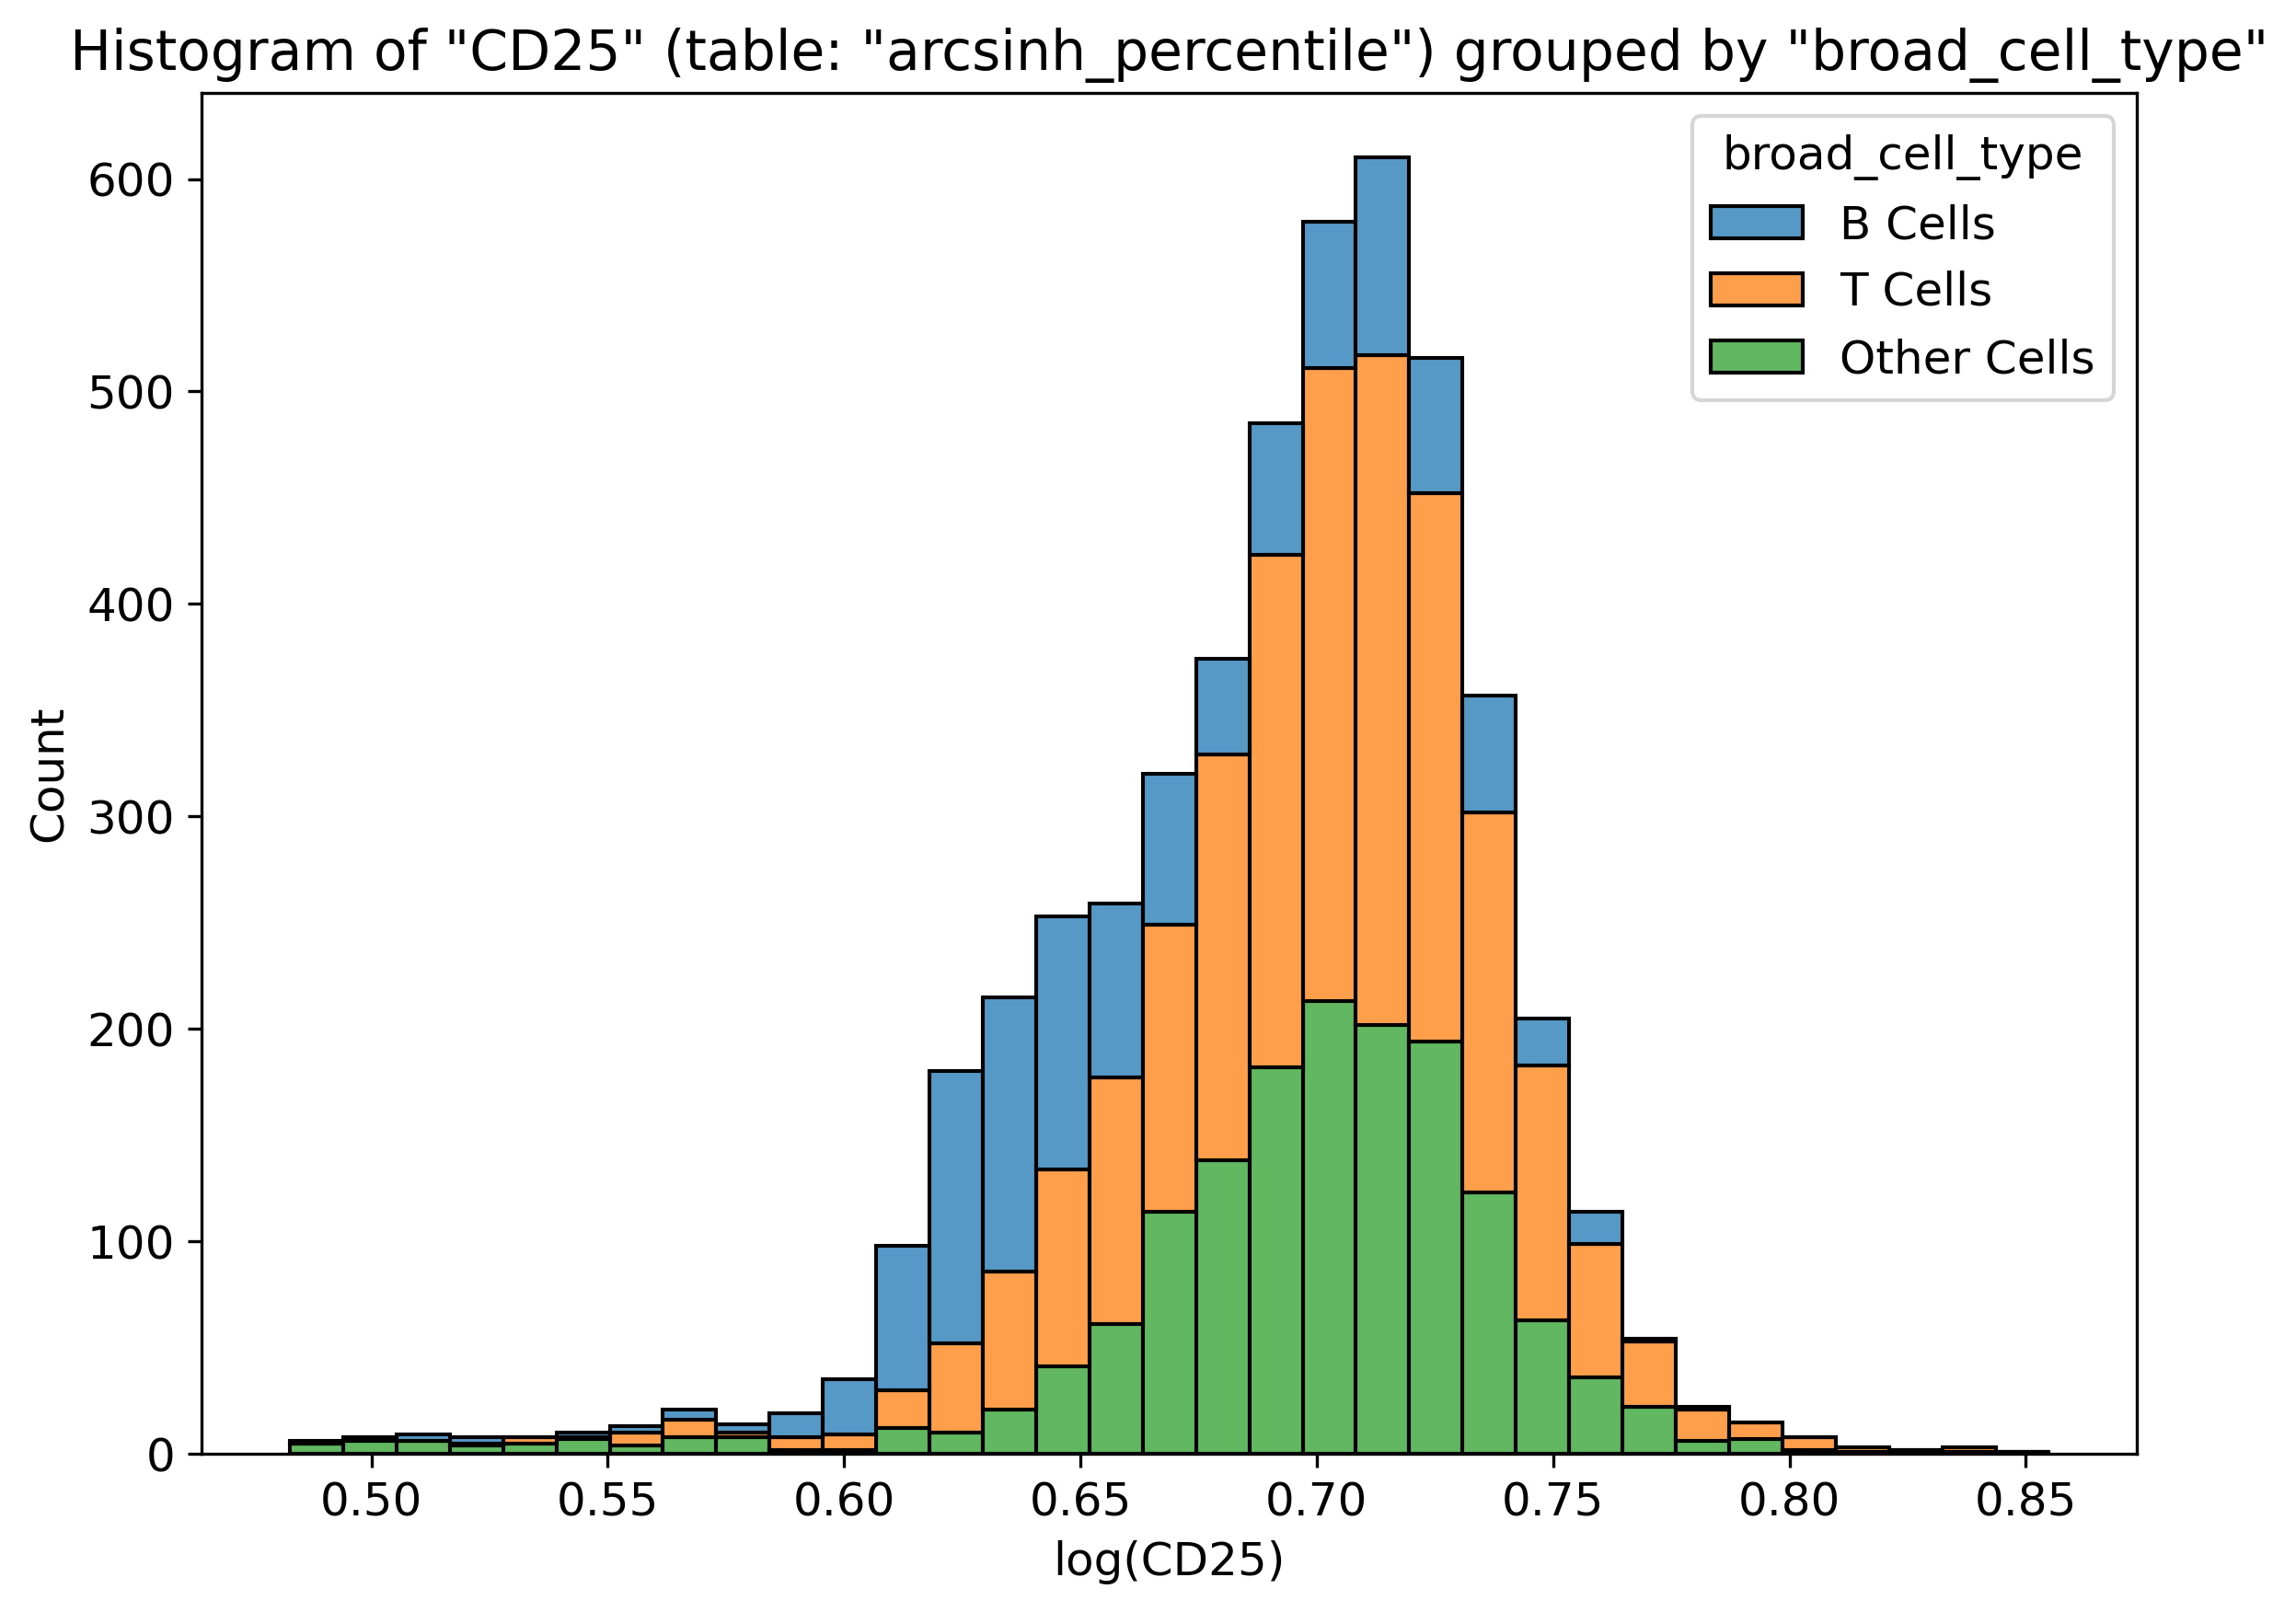

2026-11-08 13:00:38,877 - INFO - Returning figure and dataframe for in-memory use


In [5]:
# Create histogram for CD21 expression by cell type

from spac.templates.histogram_template import run_from_json

params = {
    "Upstream_Analysis": data_pickle,
    "Feature": "CD25",
    "Table_": "arcsinh_percentile",
    "Group_by": "broad_cell_type",
    "Together": True,
    "Take_X_Log": True,
    "Take_Y_Log": False,
    "Multiple": "stack",
    # "Shrink_Number": 0.8,
    "Bins": "auto",
    "Bin_Transparency": 0.75,
    "Stat": "count",
    "Plot_By": "Feature"
}

result = run_from_json(
    json_path=params,
    save_to_disk=False,
    show_plot=True
)

- Narrow figure: 4 inches wide instead of 8, with the same font size and height. Compare the title with the plot area in the preceding figure.

2026-11-08 13:00:38,903 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:38,975 - INFO - Set figure size to 4.0x6 inches.
2026-11-08 13:00:38,975 - INFO - Set figure DPI to 300.
2026-11-08 13:00:38,975 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:38,993 - INFO - Displaying top 10 rows of histogram dataframe:


   count  bin_left  bin_right  bin_center broad_cell_type
0      1  0.482752   0.494029    0.488391         B Cells
1      1  0.494029   0.505306    0.499668         B Cells
2      3  0.505306   0.516583    0.510944         B Cells
3      3  0.516583   0.527859    0.522221         B Cells
4      0  0.527859   0.539136    0.533498         B Cells
5      2  0.539136   0.550413    0.544775         B Cells
6      3  0.550413   0.561690    0.556051         B Cells
7      5  0.561690   0.572967    0.567328         B Cells
8      4  0.572967   0.584243    0.578605         B Cells
9     11  0.584243   0.595520    0.589882         B Cells


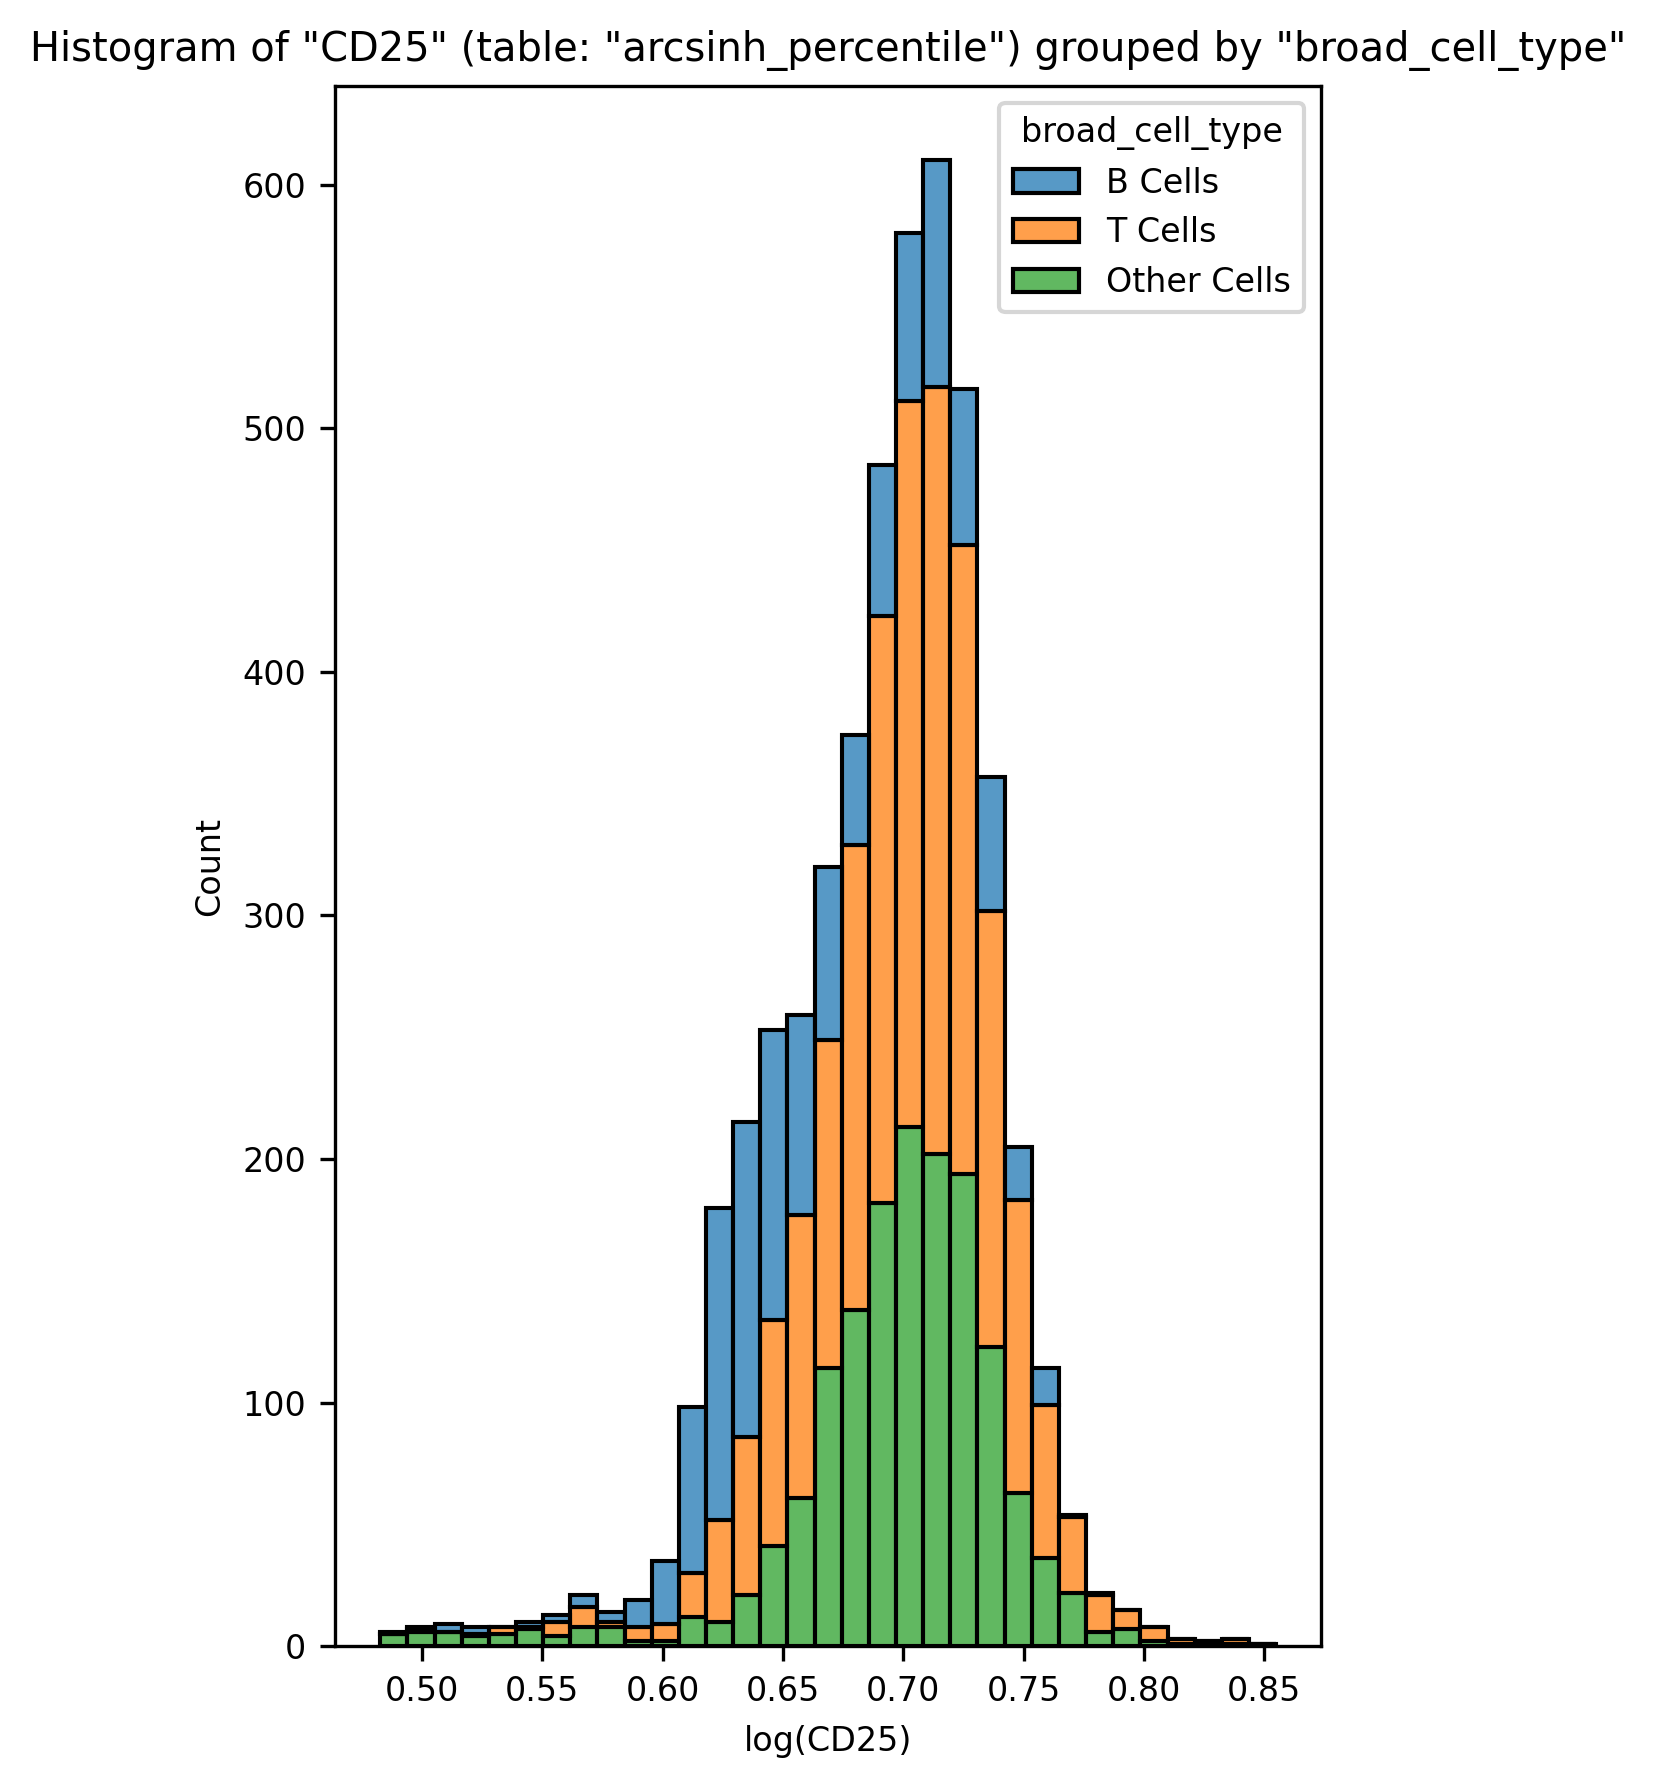

2026-11-08 13:00:39,079 - INFO - Returning figure and dataframe for in-memory use


In [6]:
result = run_from_json(
    json_path={**params, "Figure_Width": 4, "Font_Size": 8},
    save_to_disk=False,
    show_plot=True
)

- Original table

2026-11-08 13:00:39,097 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:39,133 - INFO - Set figure size to 8x6 inches.
2026-11-08 13:00:39,133 - INFO - Set figure DPI to 300.
2026-11-08 13:00:39,134 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:39,150 - INFO - Displaying top 10 rows of histogram dataframe:


   count  bin_left  bin_right  bin_center broad_cell_type
0      1  5.960594   5.990919    5.975756         B Cells
1      1  5.990919   6.021244    6.006081         B Cells
2      2  6.021244   6.051569    6.036406         B Cells
3      4  6.051569   6.081894    6.066731         B Cells
4      0  6.081894   6.112219    6.097056         B Cells
5      1  6.112219   6.142544    6.127381         B Cells
6      2  6.142544   6.172869    6.157706         B Cells
7      4  6.172869   6.203194    6.188031         B Cells
8      5  6.203194   6.233519    6.218356         B Cells
9      7  6.233519   6.263844    6.248681         B Cells


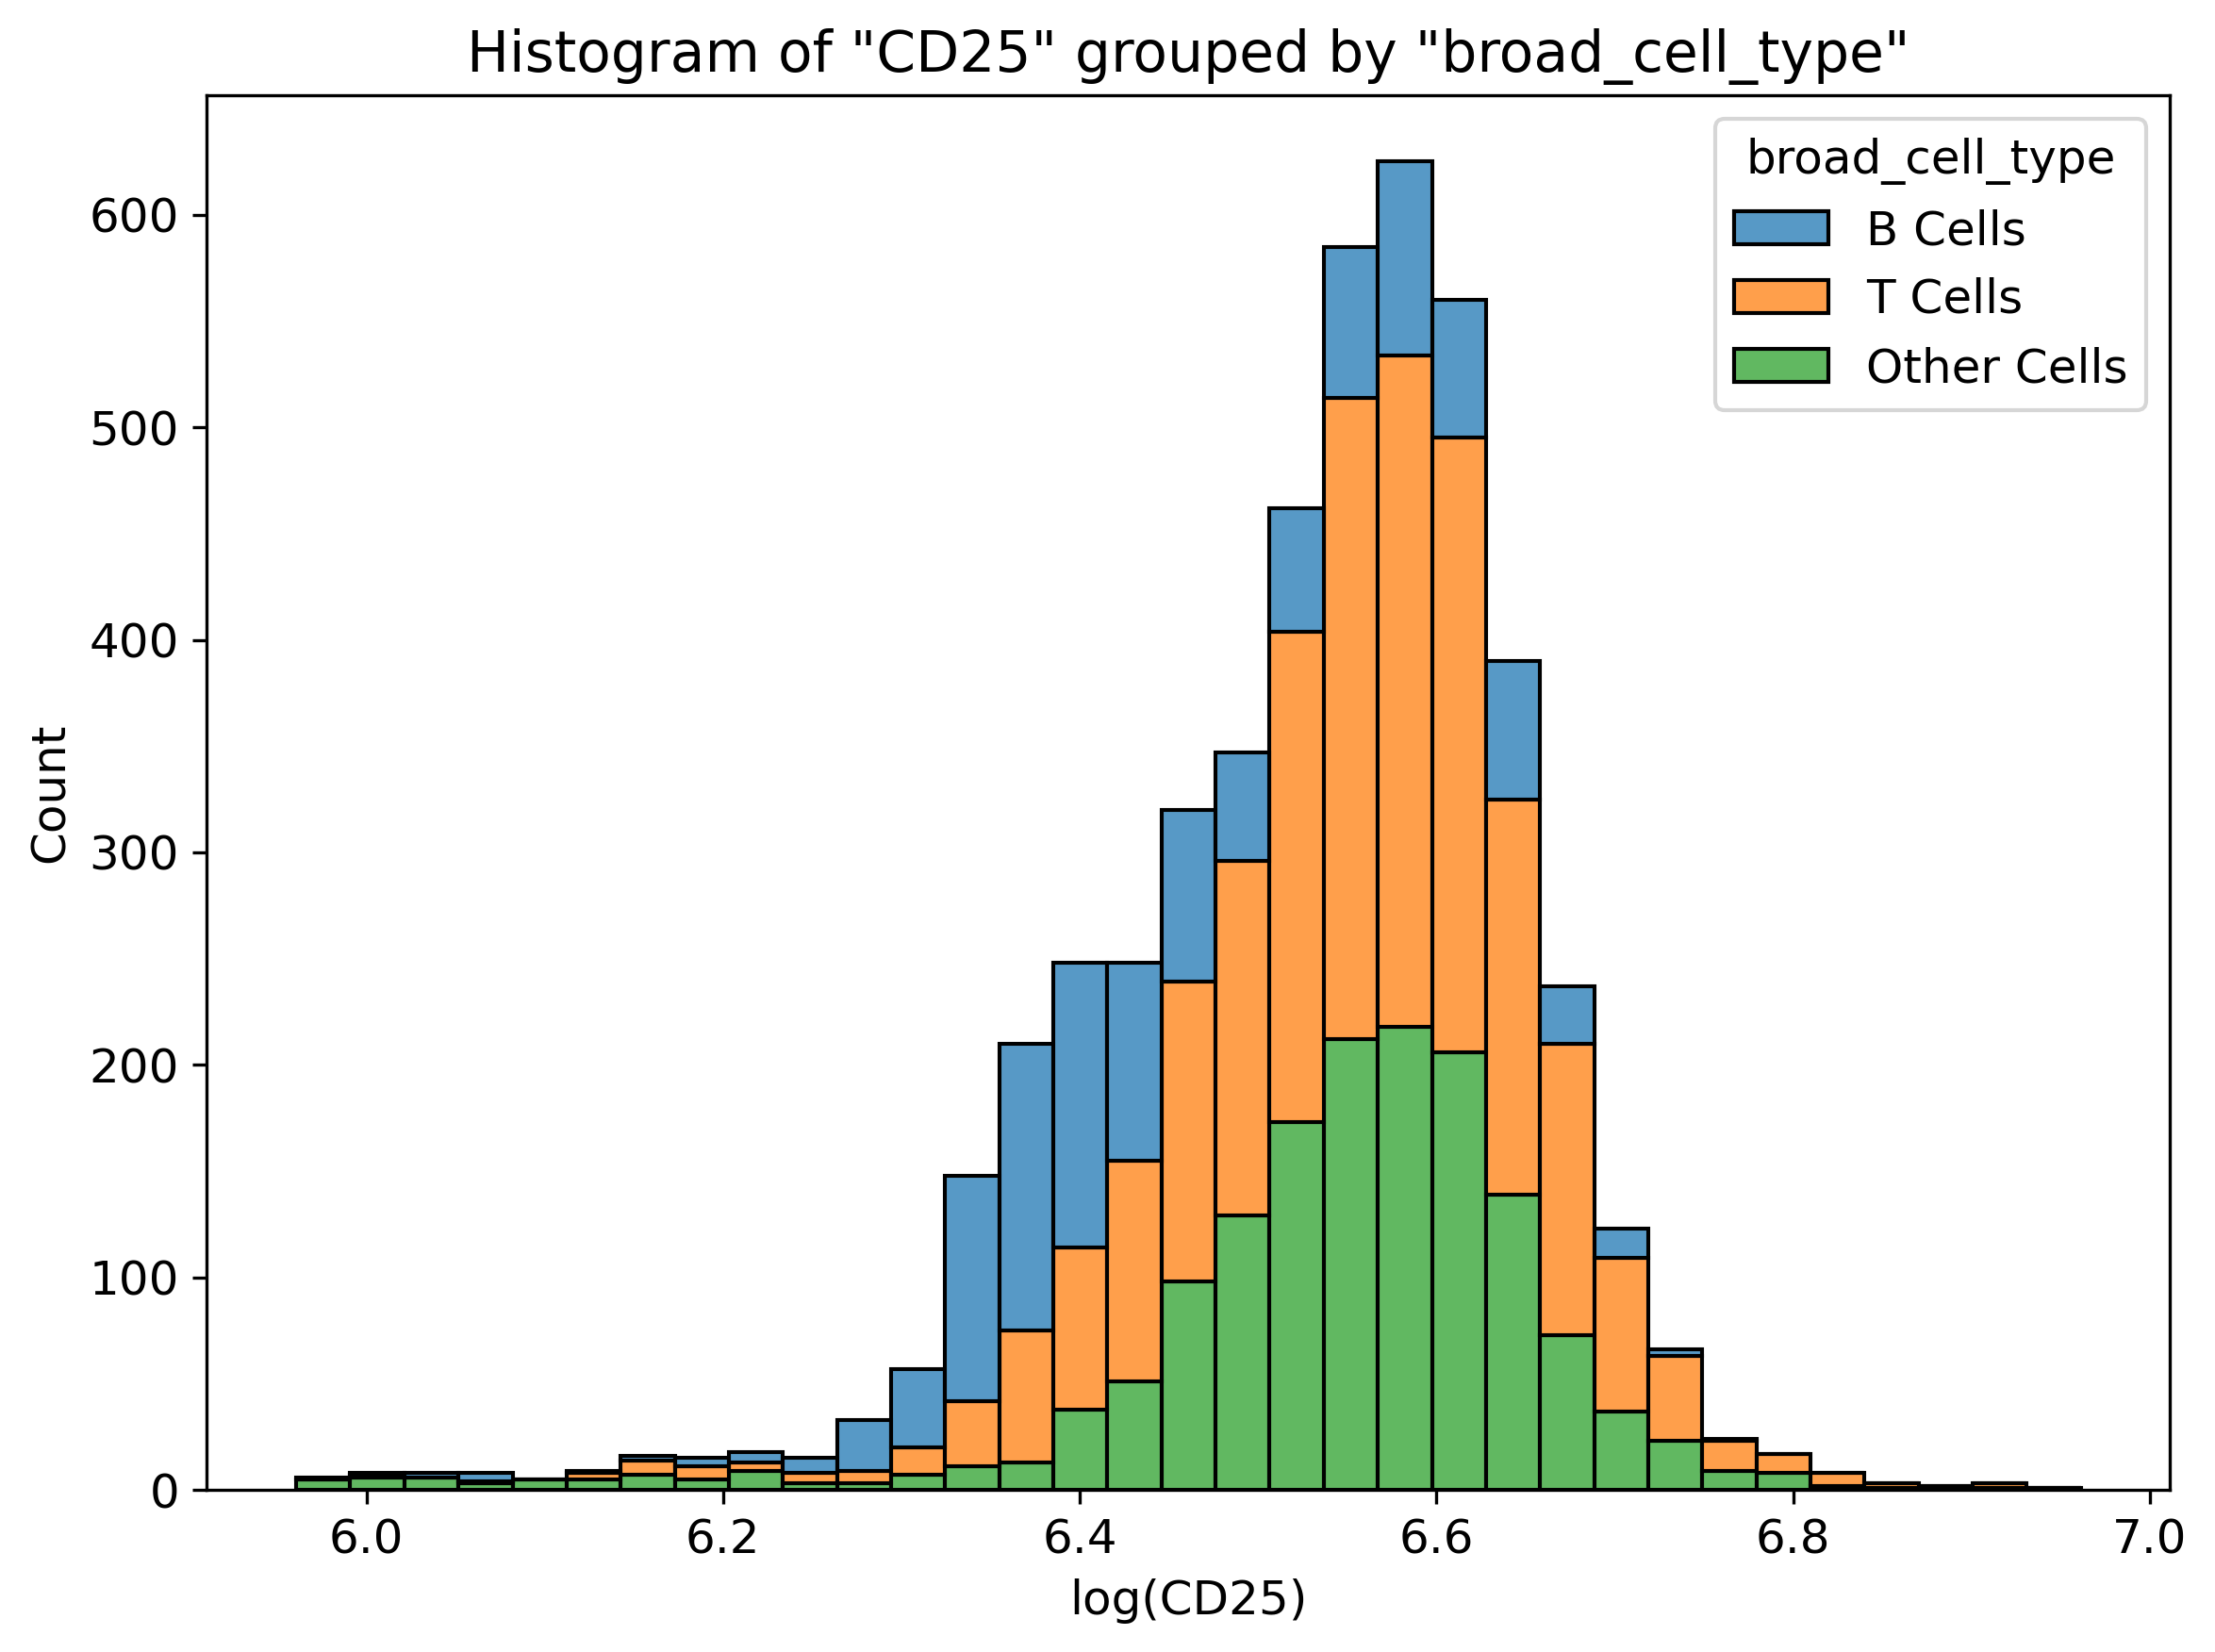

2026-11-08 13:00:39,251 - INFO - Returning figure and dataframe for in-memory use


In [7]:
params["Table_"] = "Original"

result = run_from_json(
    json_path=params,
    save_to_disk=False,
    show_plot=True
)

params["Table_"] = "arcsinh_percentile"

- Annotation

2026-11-08 13:00:39,269 - WARNING - Take X log should only apply to feature. Setting Take X Log to False.
2026-11-08 13:00:39,302 - INFO - Set figure size to 8x6 inches.
2026-11-08 13:00:39,302 - INFO - Set figure DPI to 300.
2026-11-08 13:00:39,346 - INFO - Displaying top 10 rows of histogram dataframe:


Automatically calculated number of bins is: 33
                  bin_center                   bin_left  \
0              Activated APC              Activated APC   
1         Activated T/B Cell         Activated T/B Cell   
2                     B Cell                     B Cell   
3           Cytotoxic T Cell           Cytotoxic T Cell   
4             Dendritic Cell             Dendritic Cell   
5  Follicular Dendritic Cell  Follicular Dendritic Cell   
6                Granulocyte                Granulocyte   
7              Helper T Cell              Helper T Cell   
8                 Macrophage                 Macrophage   
9                    NK Cell                    NK Cell   

                   bin_right  count broad_cell_type  
0              Activated APC      0         B Cells  
1         Activated T/B Cell      0         B Cells  
2                     B Cell    673         B Cells  
3           Cytotoxic T Cell      0         B Cells  
4             Dendritic Cell     

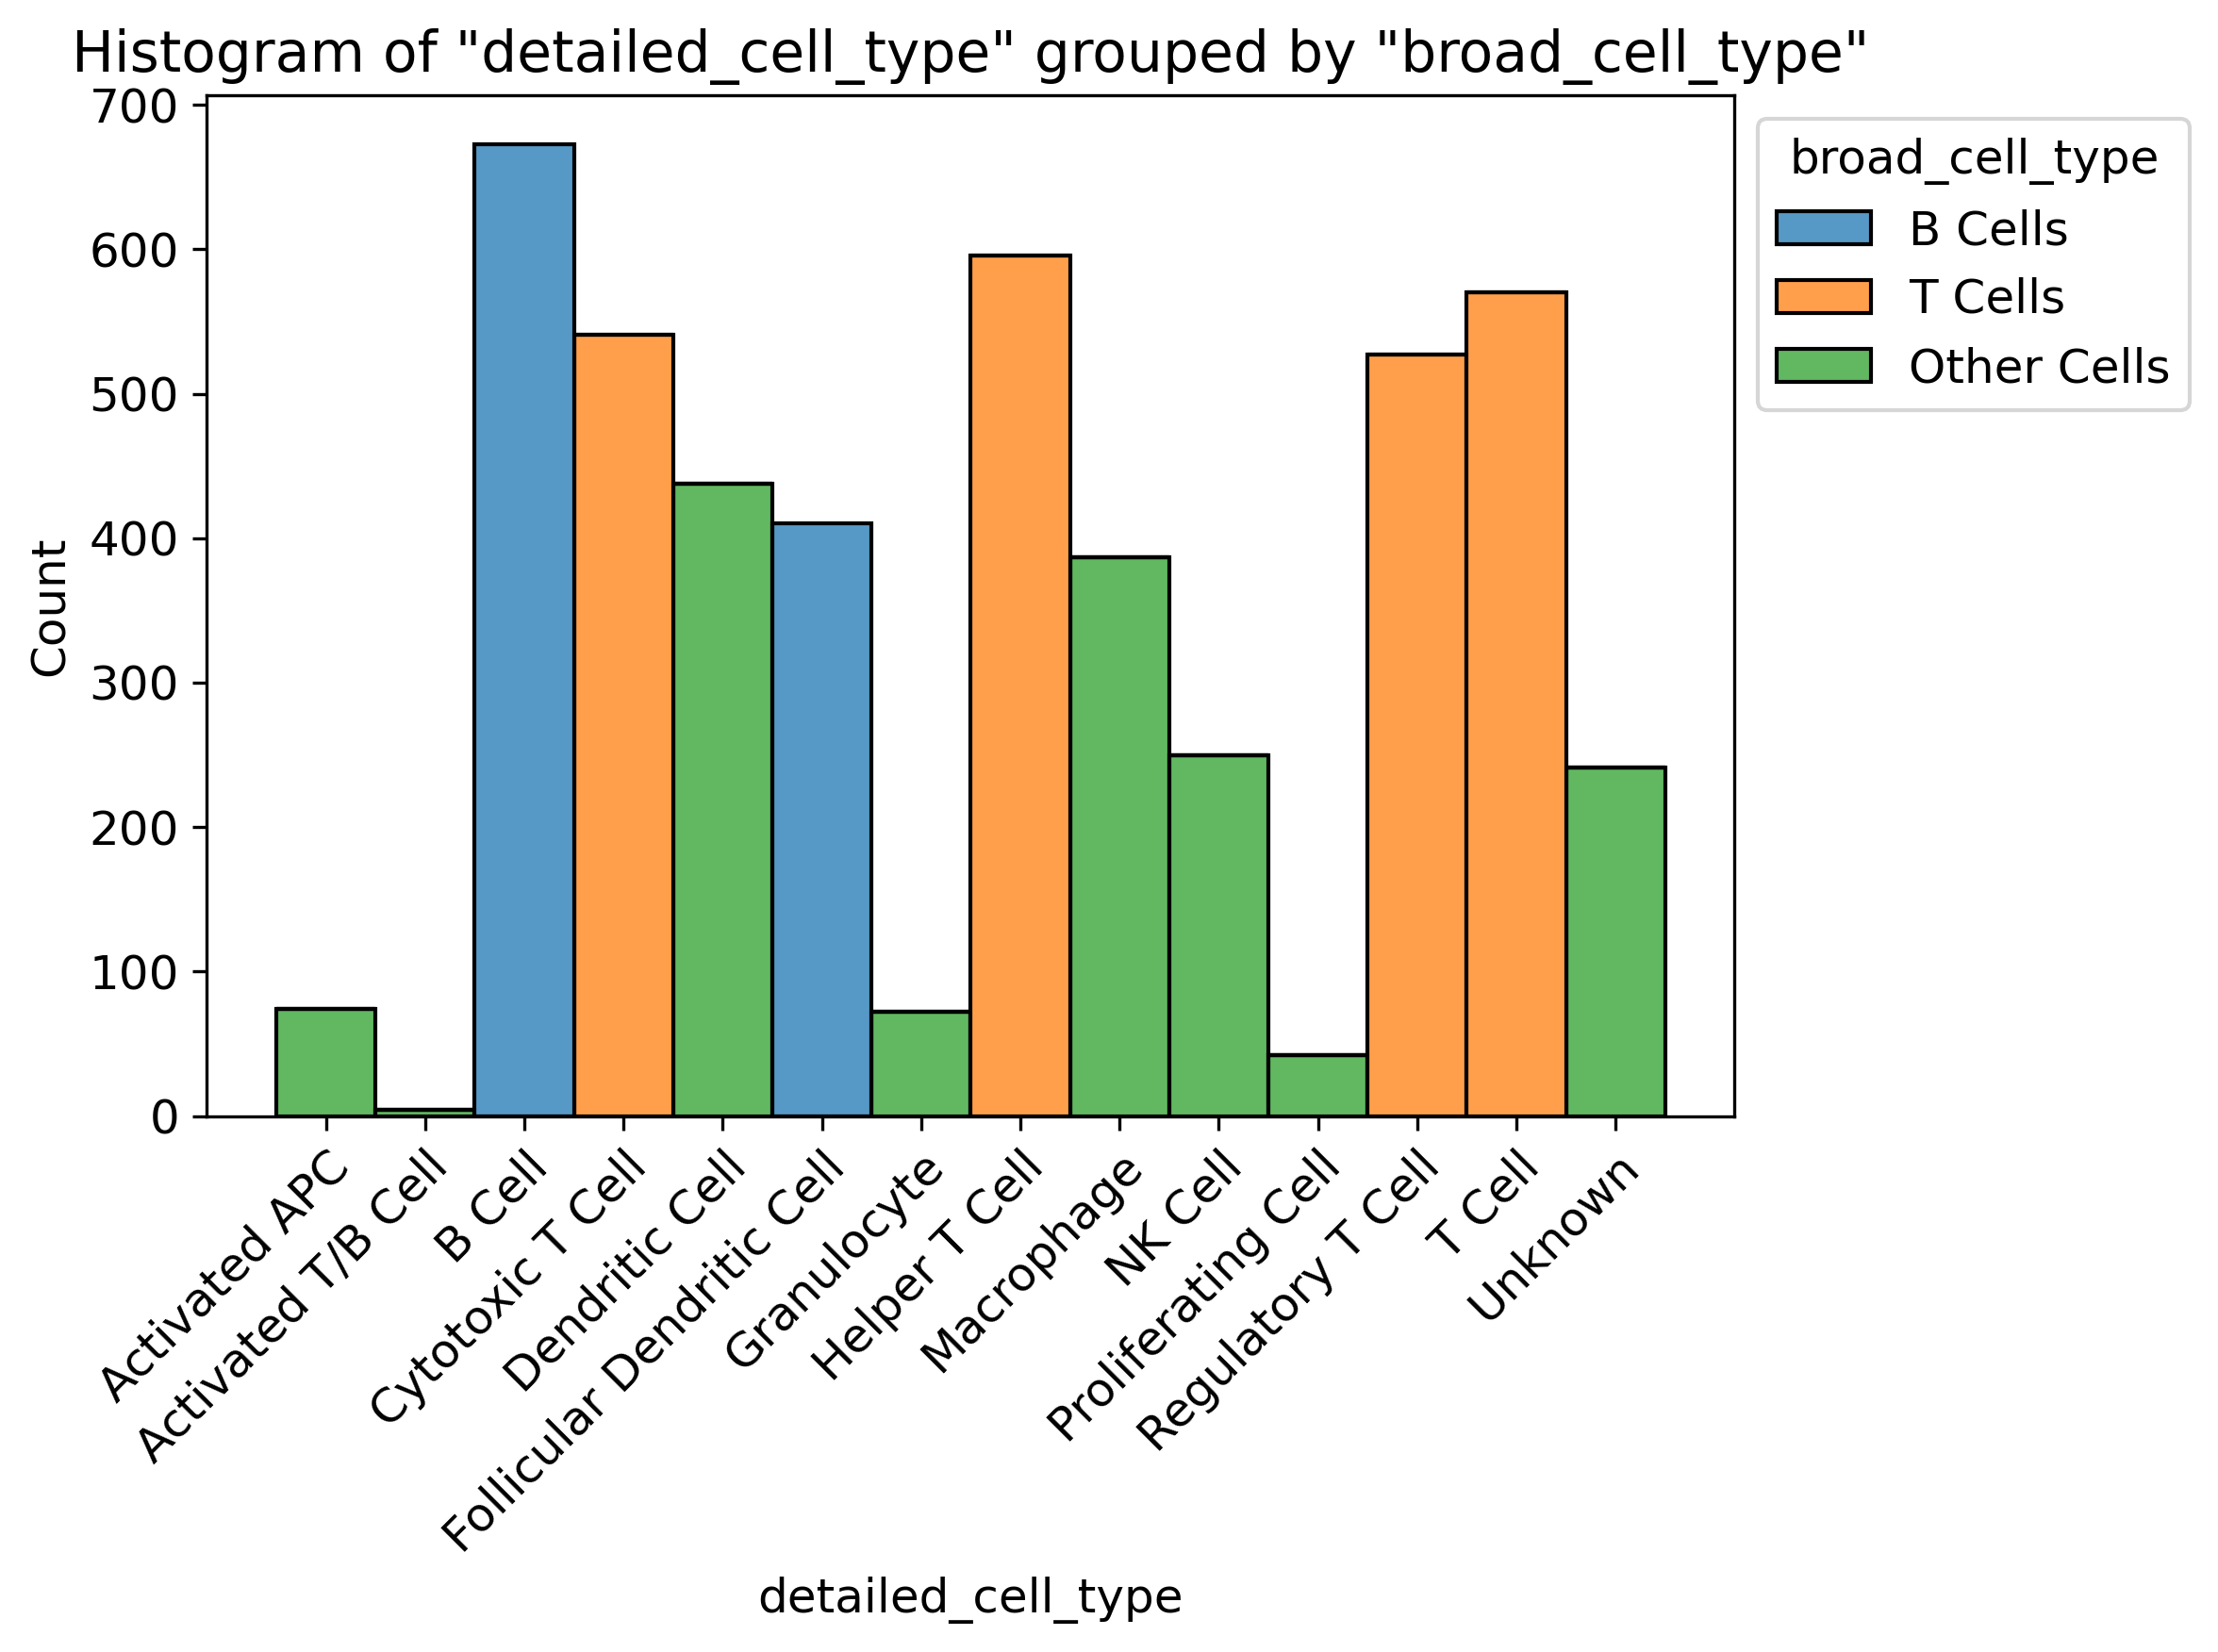

2026-11-08 13:00:39,467 - INFO - Returning figure and dataframe for in-memory use


In [8]:
params["Annotation"] = "detailed_cell_type"
params["X_Axis_Label_Rotation"] = 45
params["Plot_By"] = "Annotation"

result = run_from_json(
    json_path=params,
    save_to_disk=False,
    show_plot=True
)

params.pop("Annotation")
params.pop("X_Axis_Label_Rotation")
params["Plot_By"] = "Feature"

### 2. Many groups in group_by mode

- feature="CD25"
- layer="arcsinh_percentile"
- group_by="broad_cell_type"->"detailed_cell_type"
- together=True
- bins="auto"

2026-11-08 13:00:39,487 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:39,600 - INFO - Set figure size to 8x6 inches.
2026-11-08 13:00:39,600 - INFO - Set figure DPI to 300.
2026-11-08 13:00:39,601 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:39,648 - INFO - Displaying top 10 rows of histogram dataframe:


   count  bin_left  bin_right  bin_center detailed_cell_type
0      0  0.482752   0.494029    0.488391             B Cell
1      0  0.494029   0.505306    0.499668             B Cell
2      0  0.505306   0.516583    0.510944             B Cell
3      3  0.516583   0.527859    0.522221             B Cell
4      0  0.527859   0.539136    0.533498             B Cell
5      2  0.539136   0.550413    0.544775             B Cell
6      2  0.550413   0.561690    0.556051             B Cell
7      4  0.561690   0.572967    0.567328             B Cell
8      3  0.572967   0.584243    0.578605             B Cell
9      7  0.584243   0.595520    0.589882             B Cell


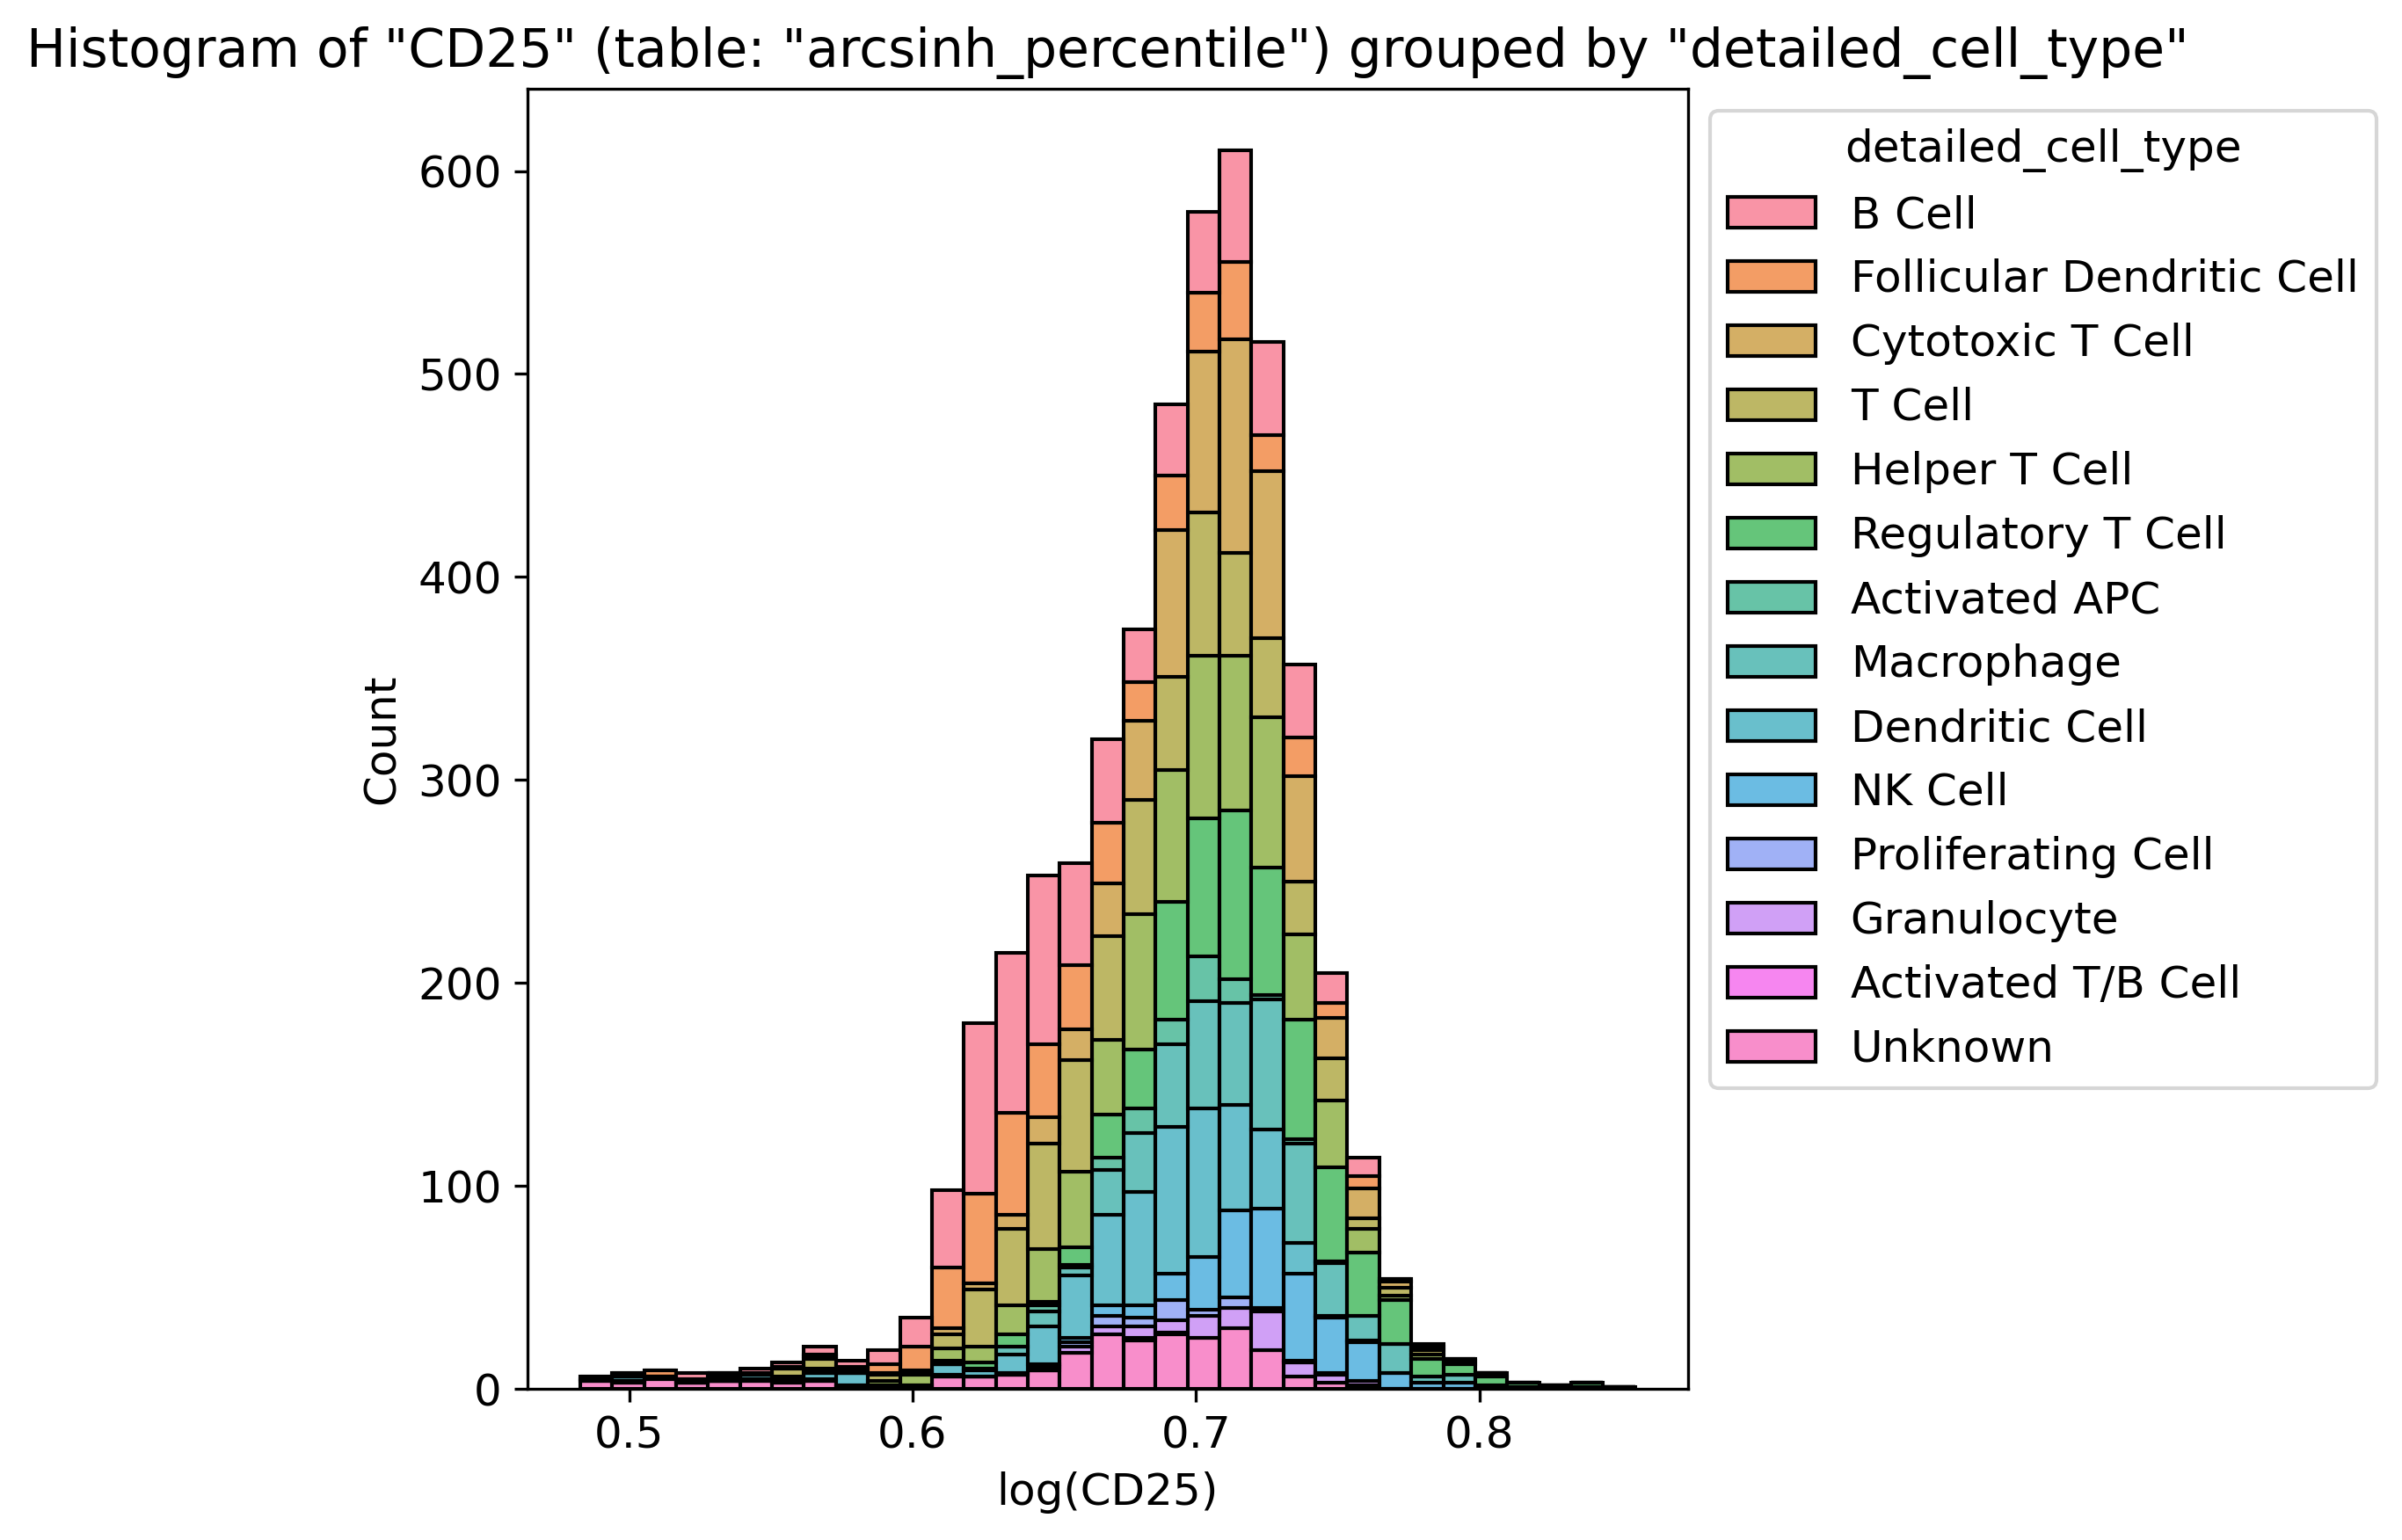

2026-11-08 13:00:39,846 - INFO - Returning figure and dataframe for in-memory use


In [9]:
params["Group_by"] = "detailed_cell_type"

result = run_from_json(
    json_path=params,
    save_to_disk=False,
    show_plot=True
)

params["Group_by"] = "broad_cell_type"

### 3. Many groups in group_by mode with filtering

- feature="CD25"
- layer="arcsinh_percentile"
- group_by="broad_cell_type"->"manual_phenotype"
- together=True
- bins="auto"

2026-11-08 13:00:39,865 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:40,060 - WARNING - The number of groups in "manual_phenotype" exceeds "max_groups": found "731", threshold "20". Plotting the 20 most frequent groups and omitting 711 groups.
2026-11-08 13:00:40,061 - INFO - Set figure size to 8x6 inches.
2026-11-08 13:00:40,062 - INFO - Set figure DPI to 300.
2026-11-08 13:00:40,062 - INFO - Plotting Feature: "CD25"
/Users/bojohnz/Dev-Repos/SCSAWorkflow/src/spac/templates/histogram_template.py:413: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()
2026-11-08 13:00:40,128 - INFO - Displaying top 10 rows of histogram dataframe:


   count  bin_left  bin_right  bin_center manual_phenotype
0      4  0.482752   0.492061    0.487407         no_label
1      1  0.492061   0.501369    0.496715         no_label
2      4  0.501369   0.510677    0.506023         no_label
3      5  0.510677   0.519985    0.515331         no_label
4      1  0.519985   0.529293    0.524639         no_label
5      4  0.529293   0.538601    0.533947         no_label
6      3  0.538601   0.547910    0.543255         no_label
7      4  0.547910   0.557218    0.552564         no_label
8      0  0.557218   0.566526    0.561872         no_label
9      4  0.566526   0.575834    0.571180         no_label


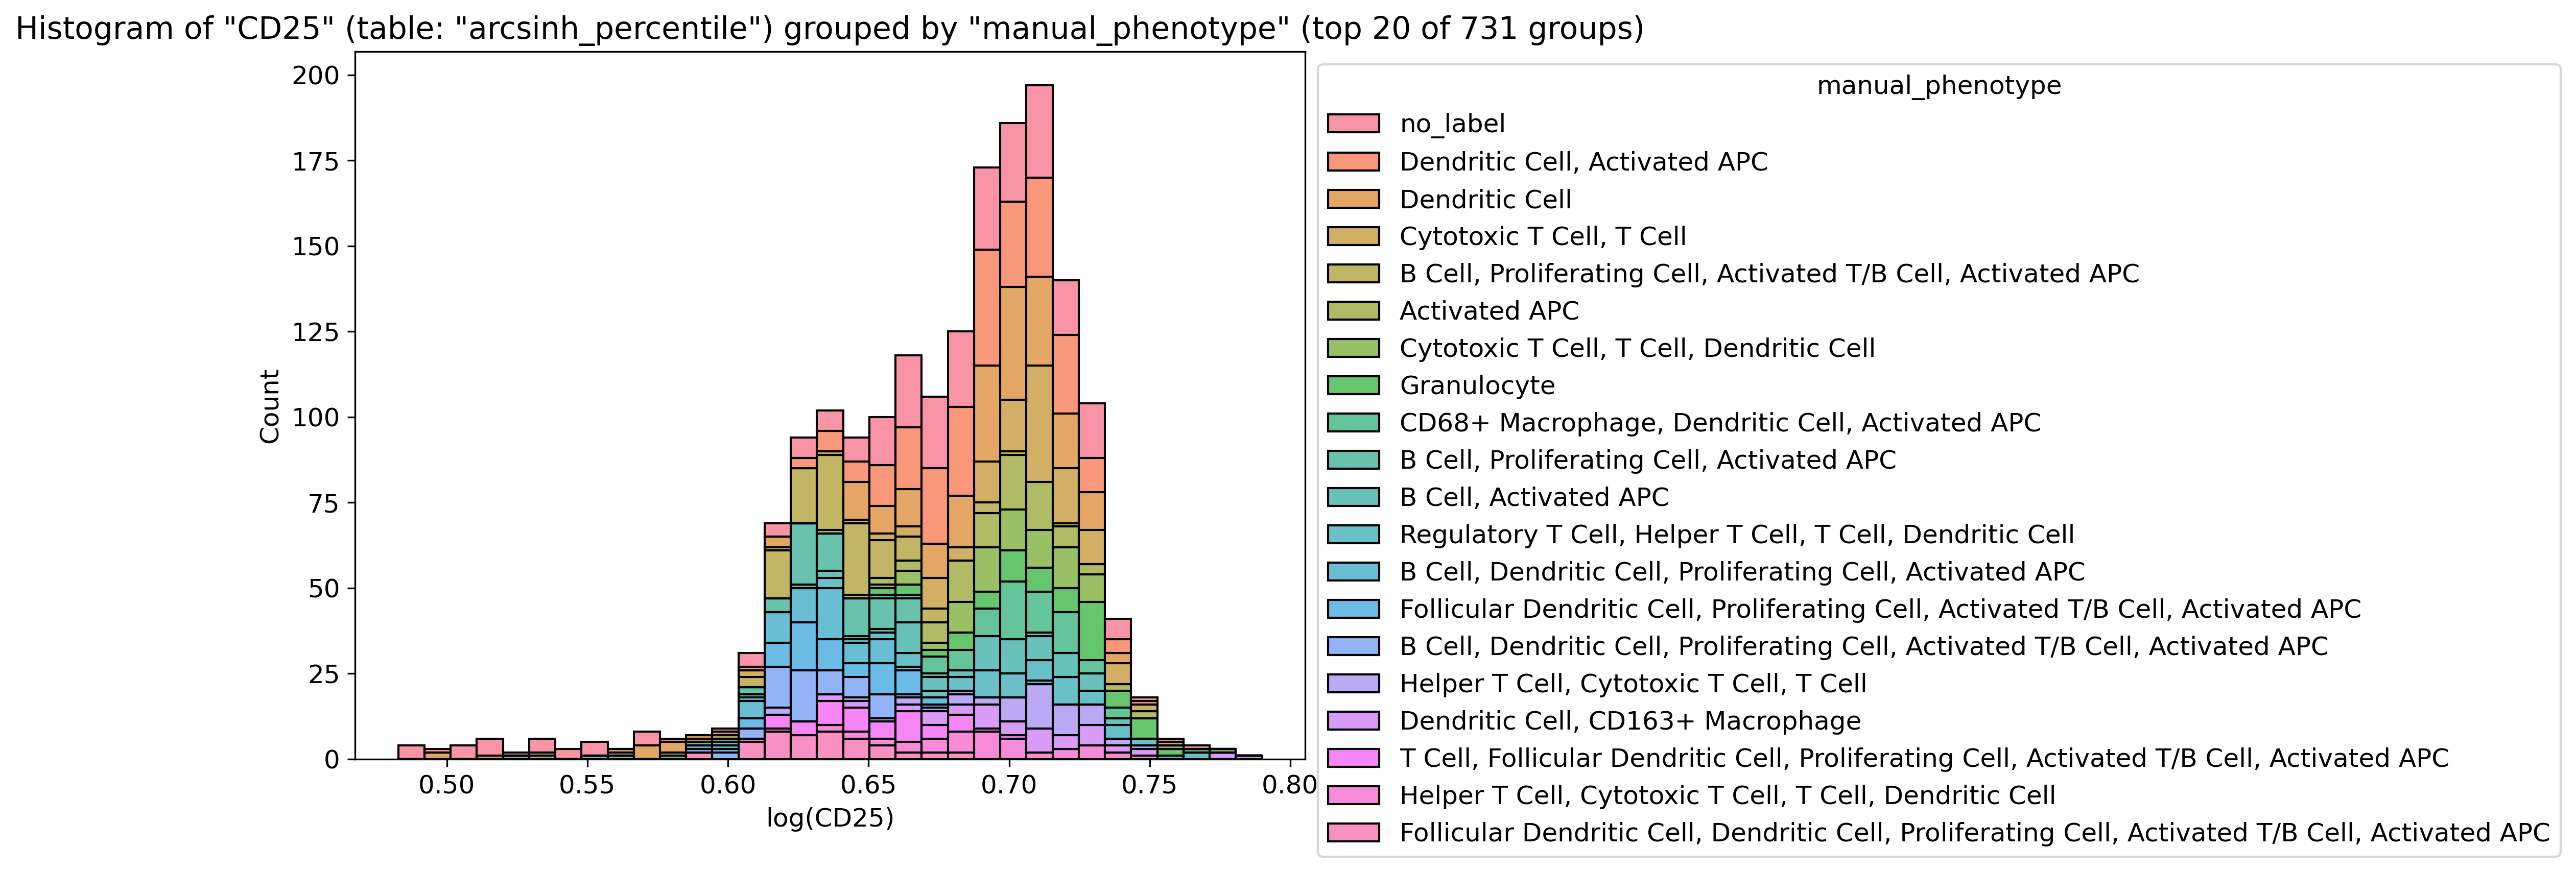

2026-11-08 13:00:40,441 - INFO - Returning figure and dataframe for in-memory use


In [10]:
params["Group_by"] = "manual_phenotype"

result = run_from_json(
    json_path=params,
    save_to_disk=False,
    show_plot=True
)

params["Group_by"] = "broad_cell_type"

- Original table

2026-11-08 13:00:40,485 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:40,643 - WARNING - The number of groups in "manual_phenotype" exceeds "max_groups": found "731", threshold "20". Plotting the 20 most frequent groups and omitting 711 groups.
2026-11-08 13:00:40,644 - INFO - Set figure size to 8x6 inches.
2026-11-08 13:00:40,645 - INFO - Set figure DPI to 300.
2026-11-08 13:00:40,645 - INFO - Plotting Feature: "CD25"
/Users/bojohnz/Dev-Repos/SCSAWorkflow/src/spac/templates/histogram_template.py:413: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()
2026-11-08 13:00:40,710 - INFO - Displaying top 10 rows of histogram dataframe:


   count  bin_left  bin_right  bin_center manual_phenotype
0      4  5.960594   5.985684    5.973139         no_label
1      1  5.985684   6.010774    5.998229         no_label
2      3  6.010774   6.035864    6.023319         no_label
3      5  6.035864   6.060954    6.048409         no_label
4      2  6.060954   6.086044    6.073499         no_label
5      2  6.086044   6.111135    6.098589         no_label
6      4  6.111135   6.136225    6.123680         no_label
7      3  6.136225   6.161315    6.148770         no_label
8      2  6.161315   6.186405    6.173860         no_label
9      4  6.186405   6.211495    6.198950         no_label


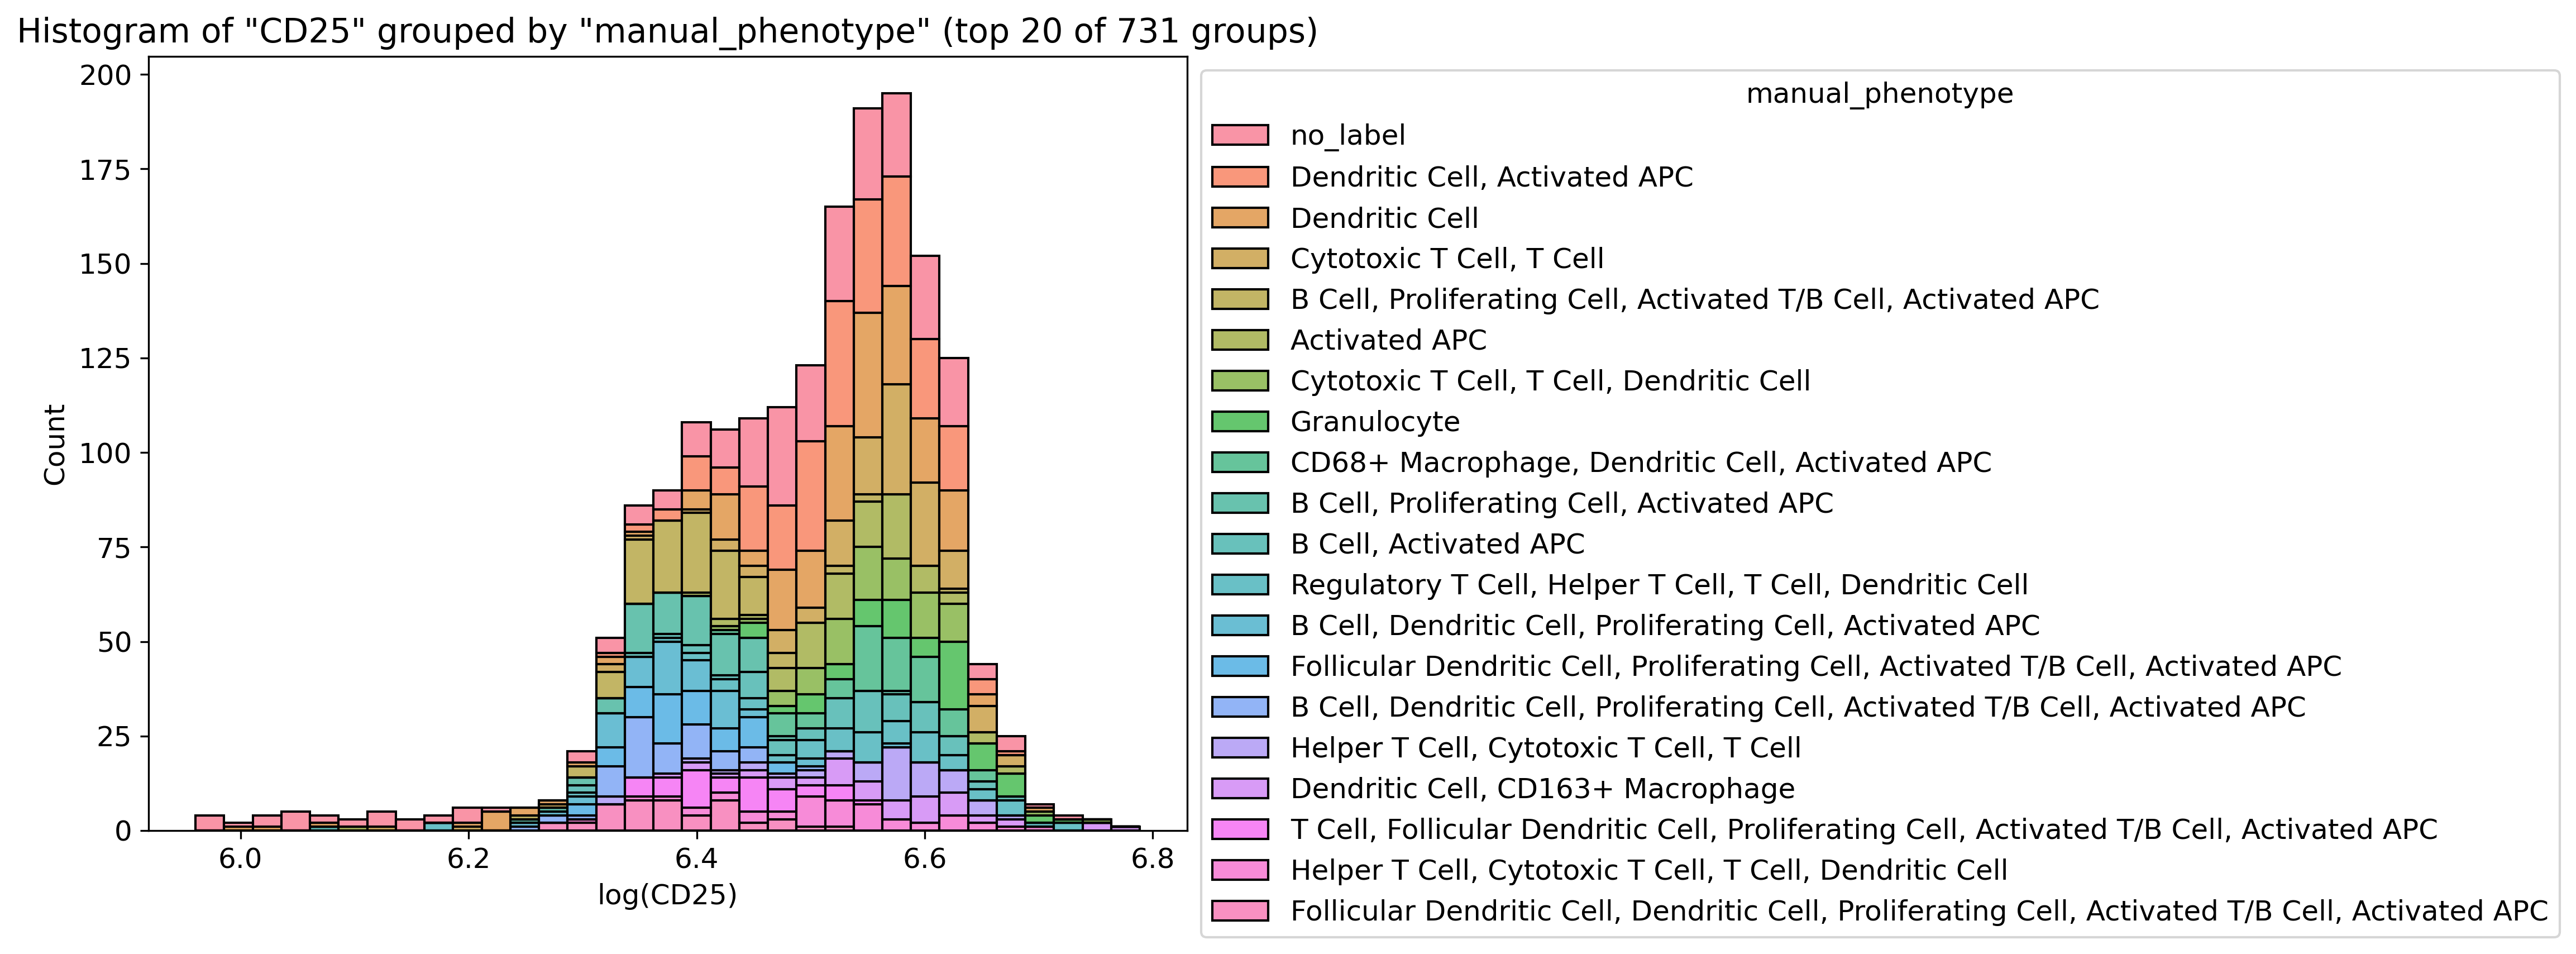

2026-11-08 13:00:41,011 - INFO - Returning figure and dataframe for in-memory use


In [11]:
params["Group_by"] = "manual_phenotype"
params["Table_"] = "Original"

result = run_from_json(
    json_path=params,
    save_to_disk=False,
    show_plot=True
)

params["Table_"] = "arcsinh_percentile"
params["Group_by"] = "broad_cell_type"

### 4. Group-separate mode (deprecated)

- feature="CD25"
- layer="arcsinh_percentile"
- group_by="broad_cell_type"->"manual_phenotype"
- together=True->False
- bins="auto"

2026-11-08 13:00:41,031 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:41,417 - WARNING - The number of groups in "manual_phenotype" exceeds "max_groups": found "731", threshold "20". Plotting the 20 most frequent groups and omitting 711 groups.
2026-11-08 13:00:41,418 - INFO - Set figure size to 8x6 inches.
2026-11-08 13:00:41,418 - INFO - Set figure DPI to 300.
2026-11-08 13:00:41,419 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,419 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,420 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,420 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,421 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,421 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,421 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,422 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,422 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:41,423 - INFO - Plottin

   count  bin_left  bin_right  bin_center
0      2  0.592759   0.595610    0.594184
1      0  0.595610   0.598460    0.597035
2      0  0.598460   0.601310    0.599885
3      0  0.601310   0.604161    0.602735
4      0  0.604161   0.607011    0.605586
5      3  0.607011   0.609861    0.608436
6      0  0.609861   0.612712    0.611286
7      4  0.612712   0.615562    0.614137
8      2  0.615562   0.618412    0.616987
9      3  0.618412   0.621263    0.619837


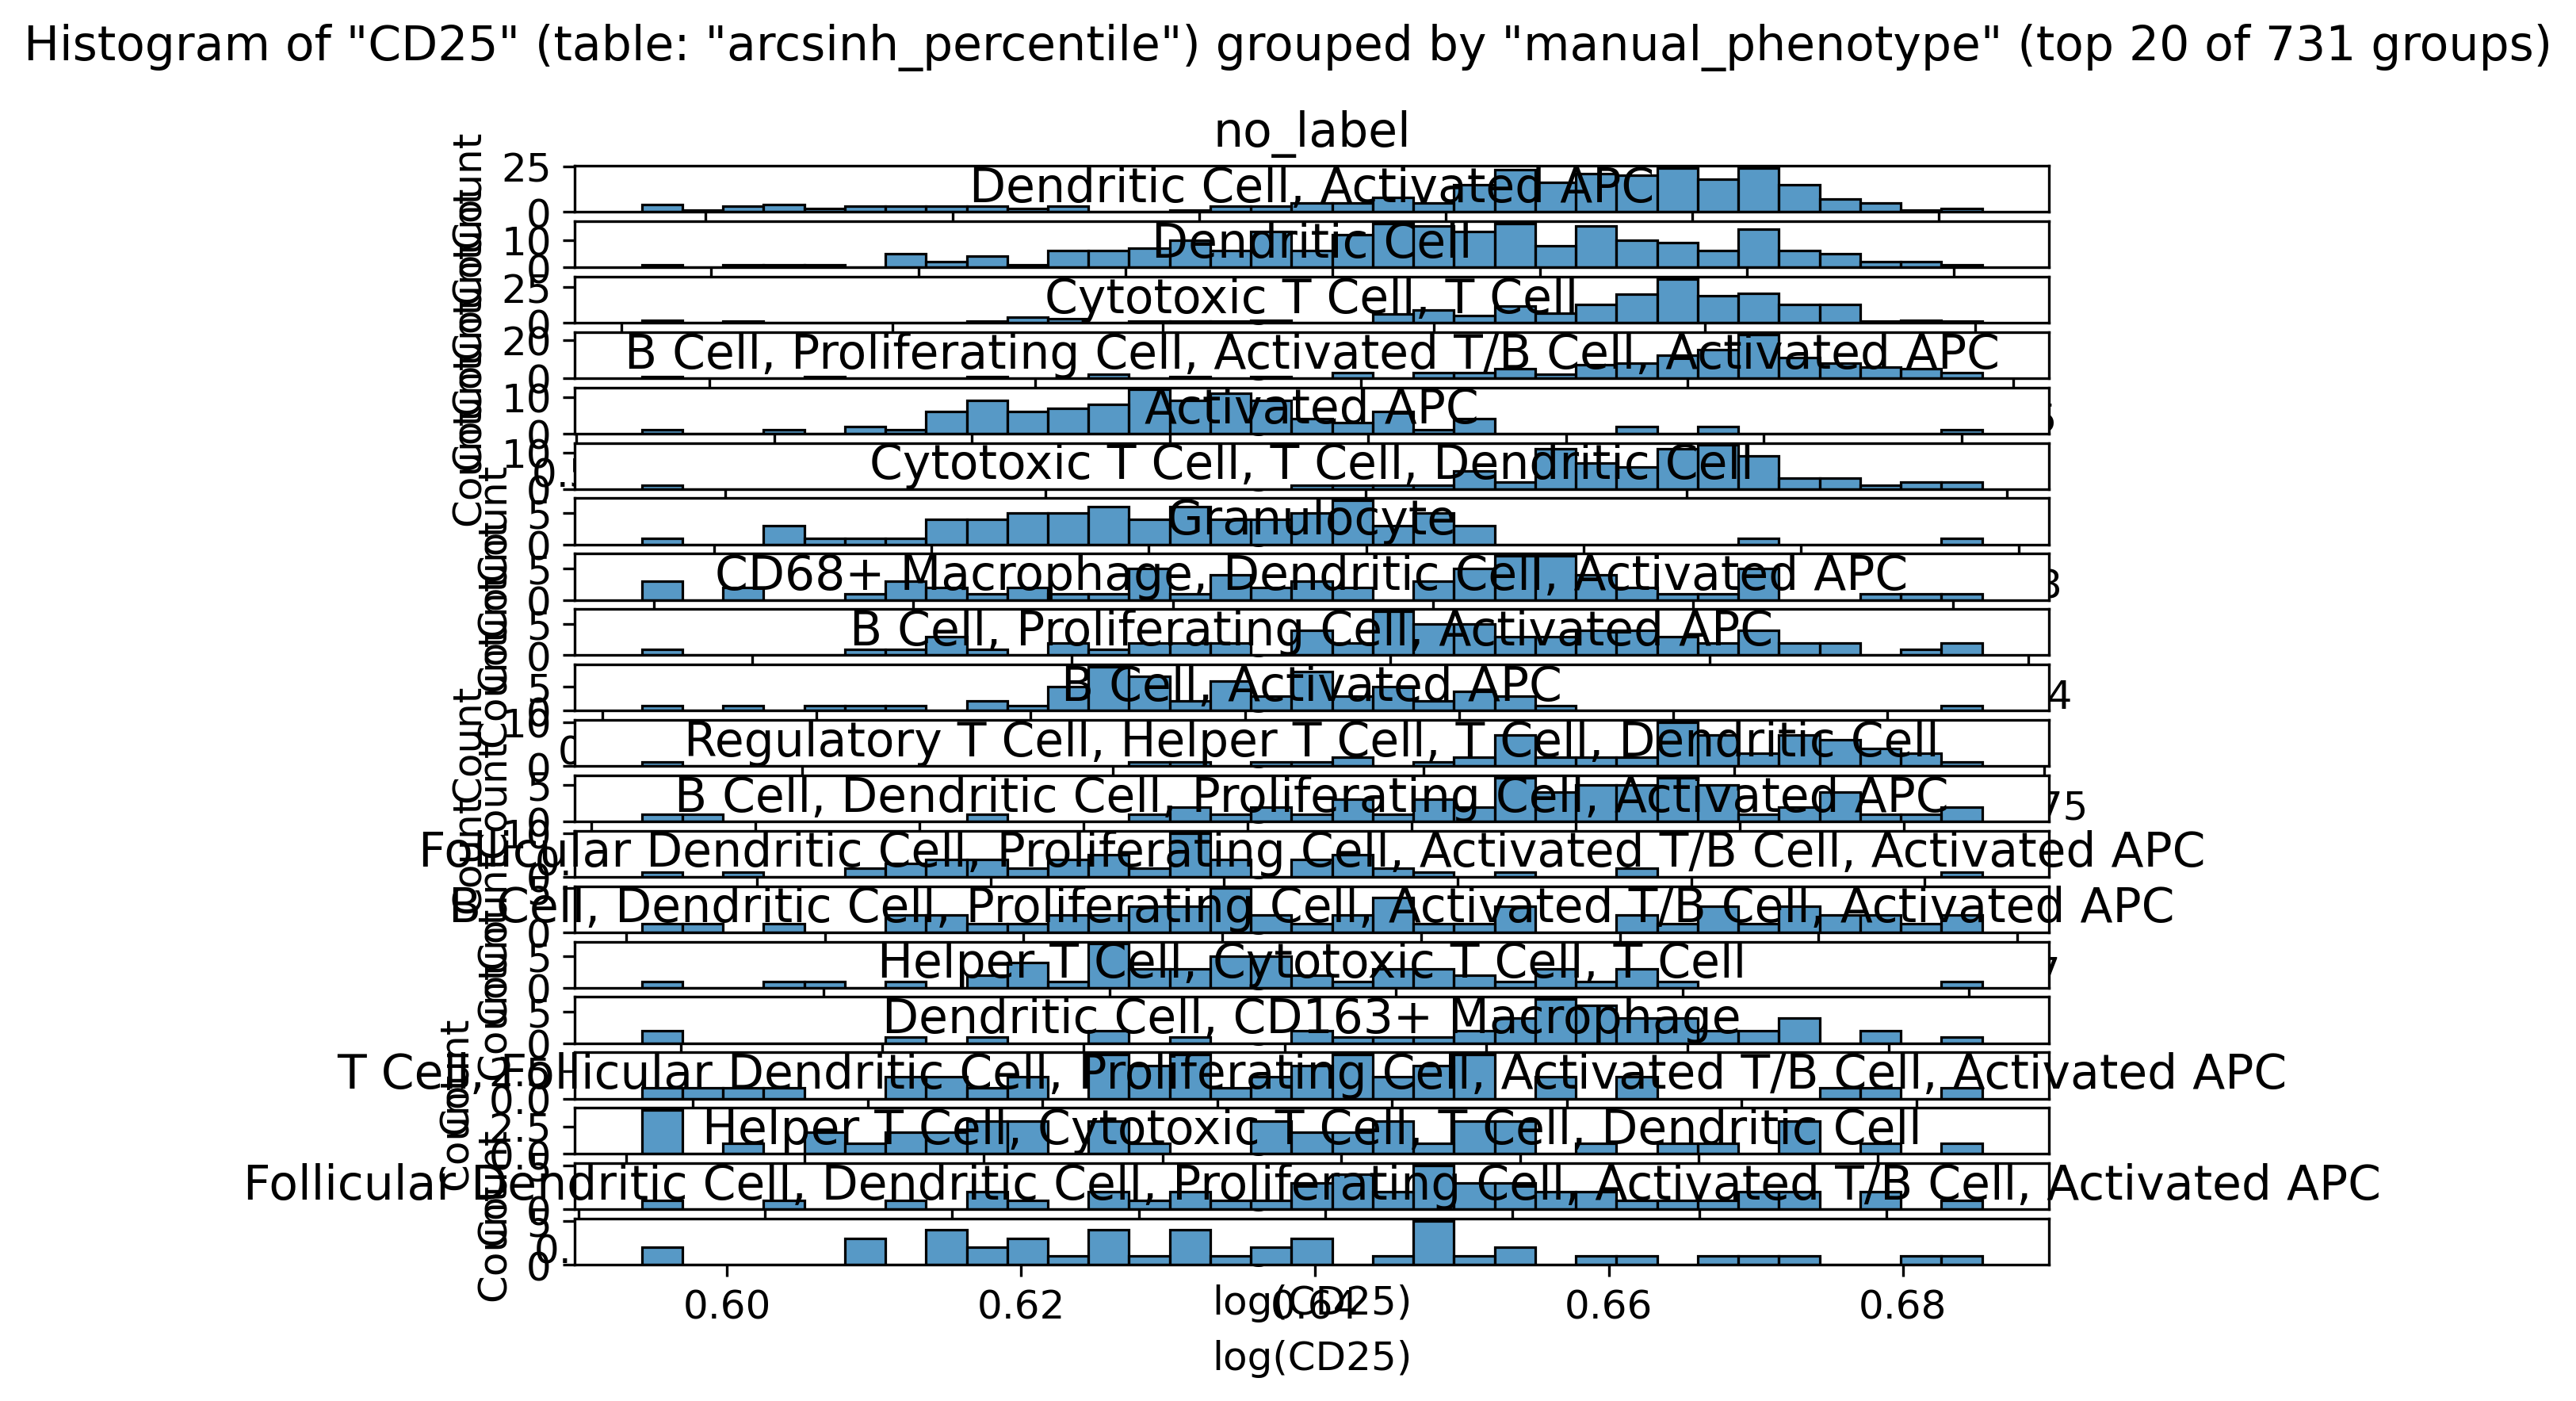

2026-11-08 13:00:42,009 - INFO - Returning figure and dataframe for in-memory use


In [12]:
params["Group_by"] = "manual_phenotype"
params["Together"] = False

result = run_from_json(
    json_path=params,
    save_to_disk=False,
    show_plot=True
)

params["Group_by"] = "broad_cell_type"
params["Together"] = True

### 5. Facet mode

- feature="CD25"
- layer="arcsinh_percentile"
- group_by="broad_cell_type"->"manual_phenotype"
- together=True->False
- bins="auto"
- facet=False->True

2026-11-08 13:00:42,031 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:42,034 - INFO - Automatic facet_ncol selection: 5 columns for 20 groups (vertical_threshold=3).
2026-11-08 13:00:42,960 - WARNING - The number of groups in "manual_phenotype" exceeds "max_groups": found "731", threshold "20". Plotting the 20 most frequent groups and omitting 711 groups.
2026-11-08 13:00:42,961 - INFO - Set figure DPI to 300.
2026-11-08 13:00:42,961 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:42,962 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:42,962 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:42,963 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:42,963 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:42,963 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:42,964 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:42,964 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:42,965 - INFO - Plotting Feature

   count  bin_left  bin_right  bin_center manual_phenotype
0      4  0.482752   0.492061    0.487407         no_label
1      1  0.492061   0.501369    0.496715         no_label
2      4  0.501369   0.510677    0.506023         no_label
3      5  0.510677   0.519985    0.515331         no_label
4      1  0.519985   0.529293    0.524639         no_label
5      4  0.529293   0.538601    0.533947         no_label
6      3  0.538601   0.547910    0.543255         no_label
7      4  0.547910   0.557218    0.552564         no_label
8      0  0.557218   0.566526    0.561872         no_label
9      4  0.566526   0.575834    0.571180         no_label


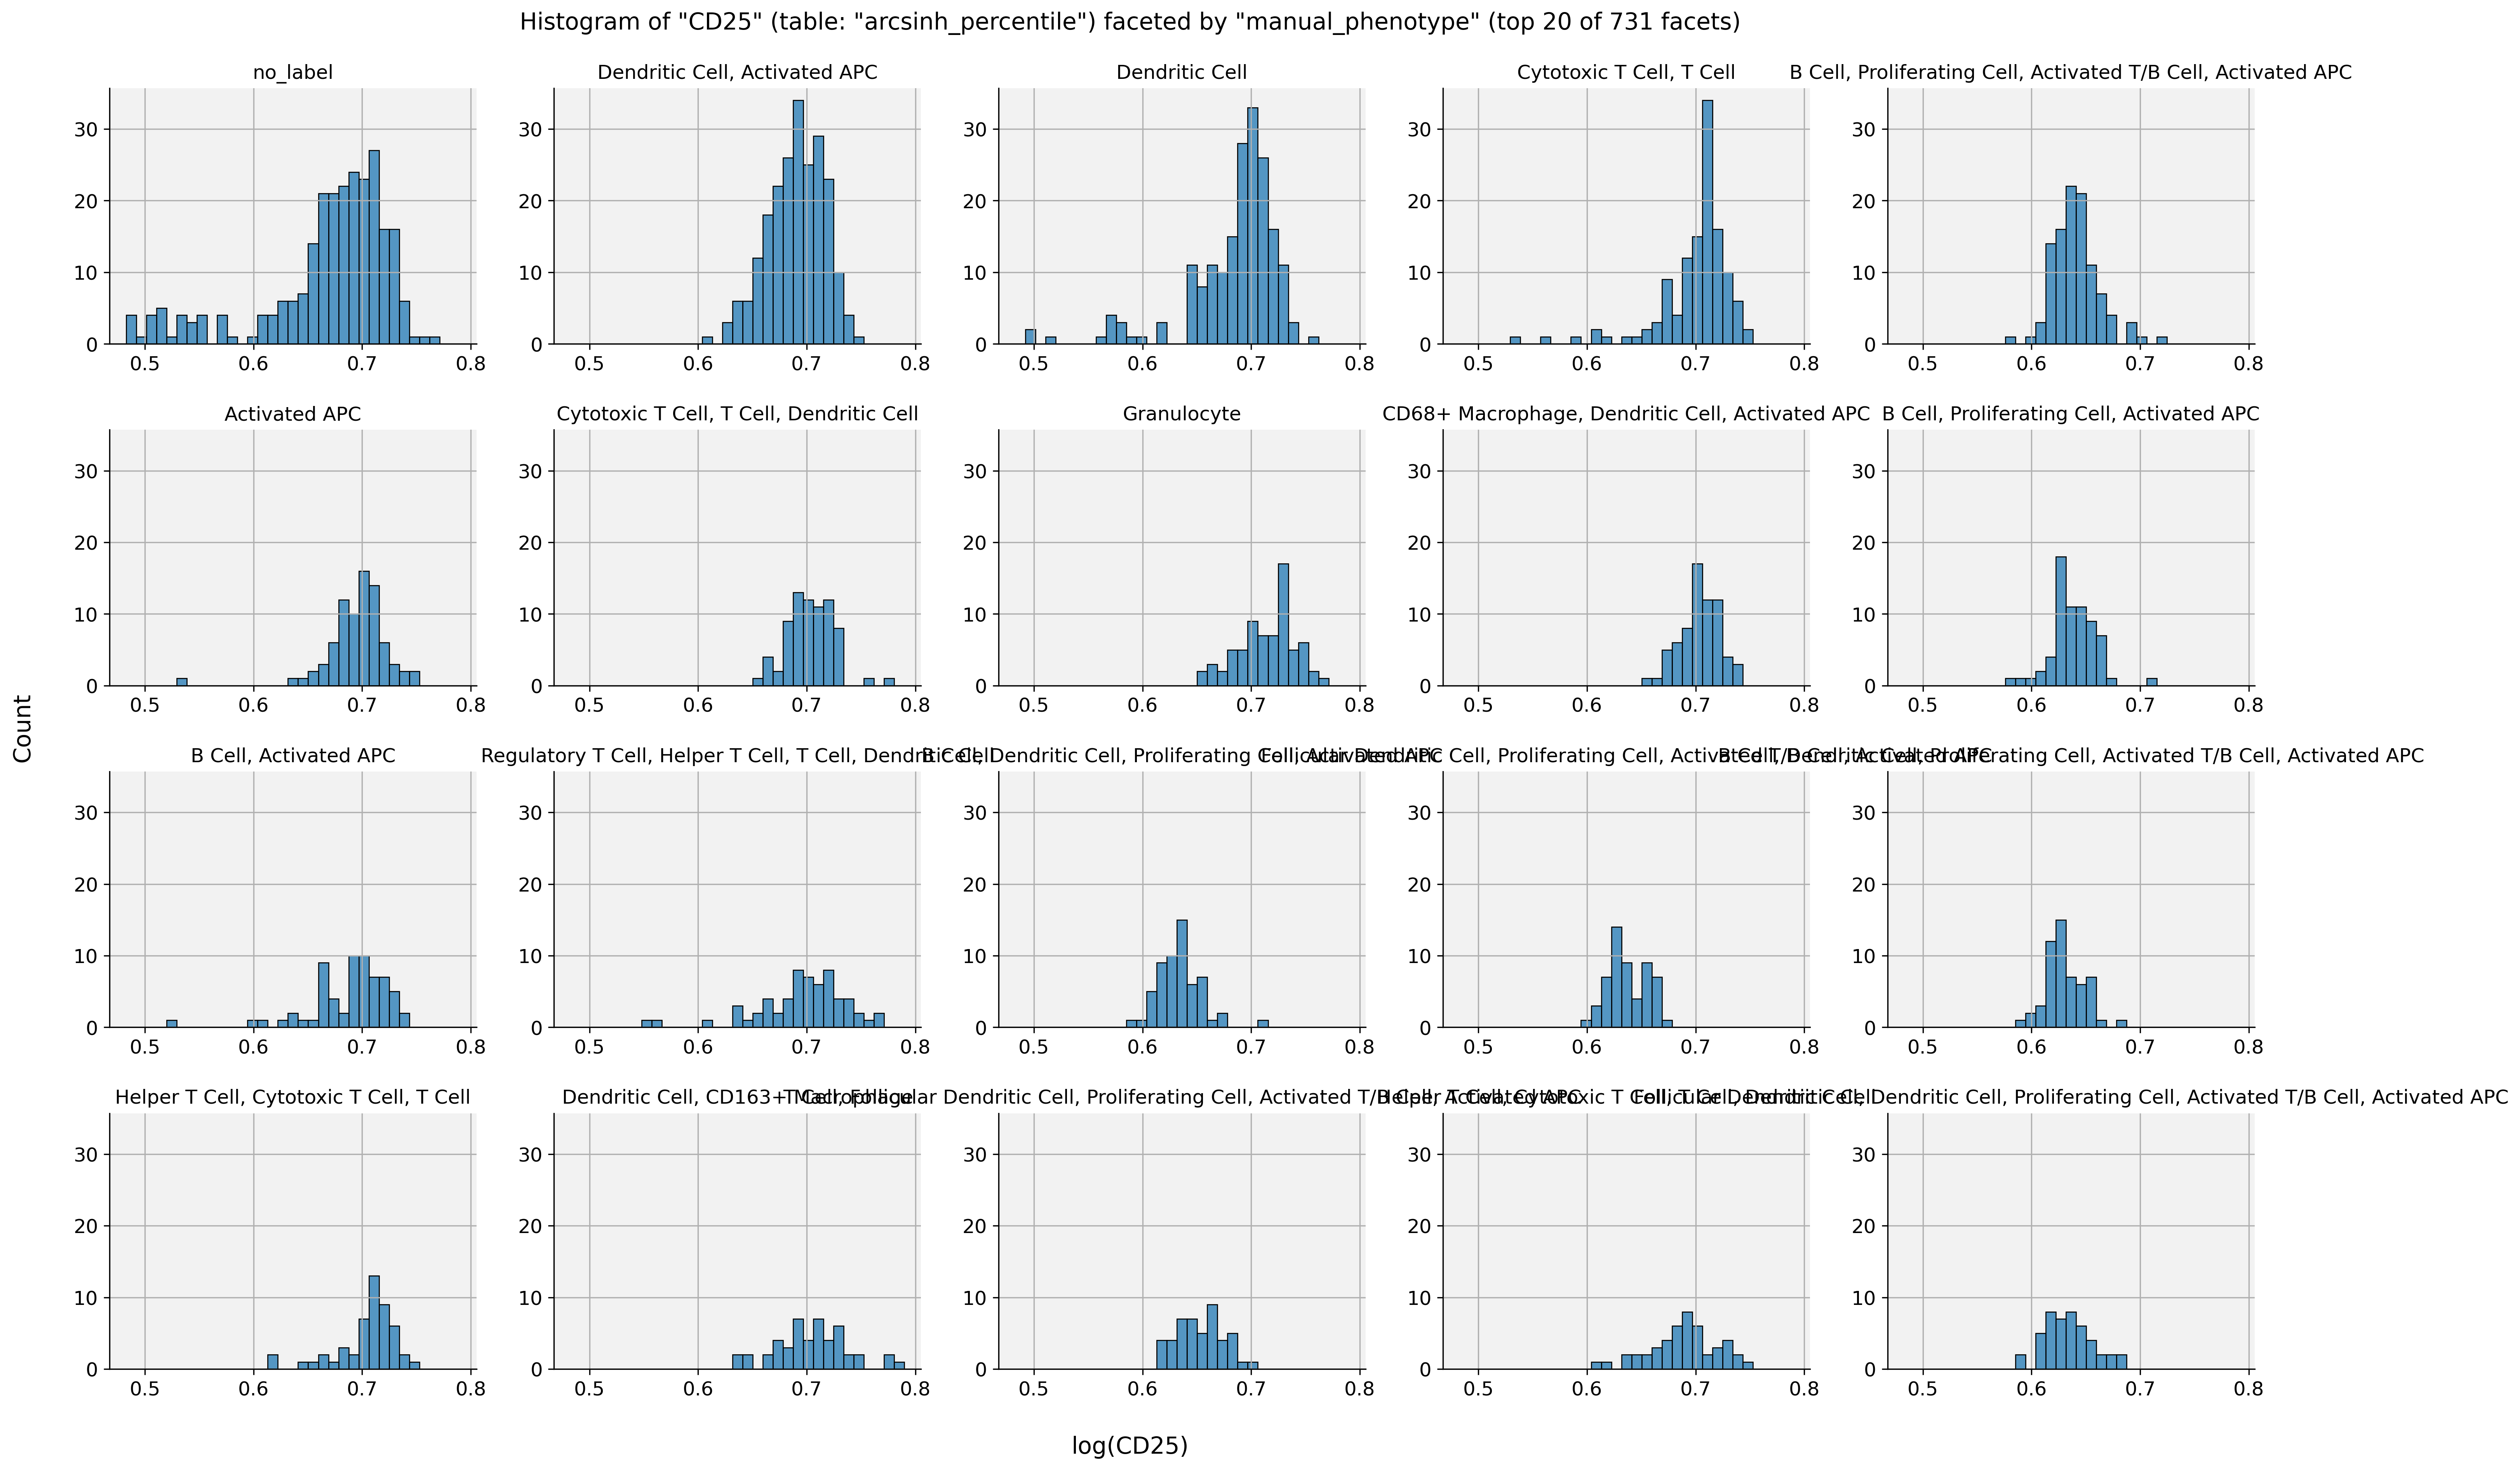

2026-11-08 13:00:43,881 - INFO - Returning figure and dataframe for in-memory use


In [13]:
params["Group_by"] = "manual_phenotype"
params["Together"] = False
params["Facet"] = True

result = run_from_json(
    json_path=params,
    save_to_disk=False,
    show_plot=True
)

params["Group_by"] = "broad_cell_type"
params["Together"] = True
params["Facet"] = False

Facet comparison with readable labels

Show the six most frequent groups in two columns, using a larger figure and higher DPI for a clearer before-and-after comparison.

2026-11-08 13:00:43,904 - INFO - Bins not specified. Setting bins to 33 using the 2 * n^(1/3) rule of thumb with n=4825 rows.
2026-11-08 13:00:44,158 - WARNING - The number of groups in "manual_phenotype" exceeds "max_groups": found "731", threshold "6". Plotting the 6 most frequent groups and omitting 725 groups.
2026-11-08 13:00:44,158 - INFO - Set figure size to 18.0x10.0 inches.
2026-11-08 13:00:44,158 - INFO - Set figure DPI to 160.
2026-11-08 13:00:44,159 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:44,159 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:44,160 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:44,160 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:44,161 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:44,162 - INFO - Plotting Feature: "CD25"
2026-11-08 13:00:44,225 - INFO - Displaying top 10 rows of histogram dataframe:


   count  bin_left  bin_right  bin_center manual_phenotype
0      4  0.482752   0.491246    0.486999         no_label
1      1  0.491246   0.499739    0.495493         no_label
2      3  0.499739   0.508233    0.503986         no_label
3      4  0.508233   0.516726    0.512479         no_label
4      2  0.516726   0.525219    0.520973         no_label
5      3  0.525219   0.533713    0.529466         no_label
6      3  0.533713   0.542206    0.537960         no_label
7      3  0.542206   0.550700    0.546453         no_label
8      3  0.550700   0.559193    0.554946         no_label
9      2  0.559193   0.567687    0.563440         no_label


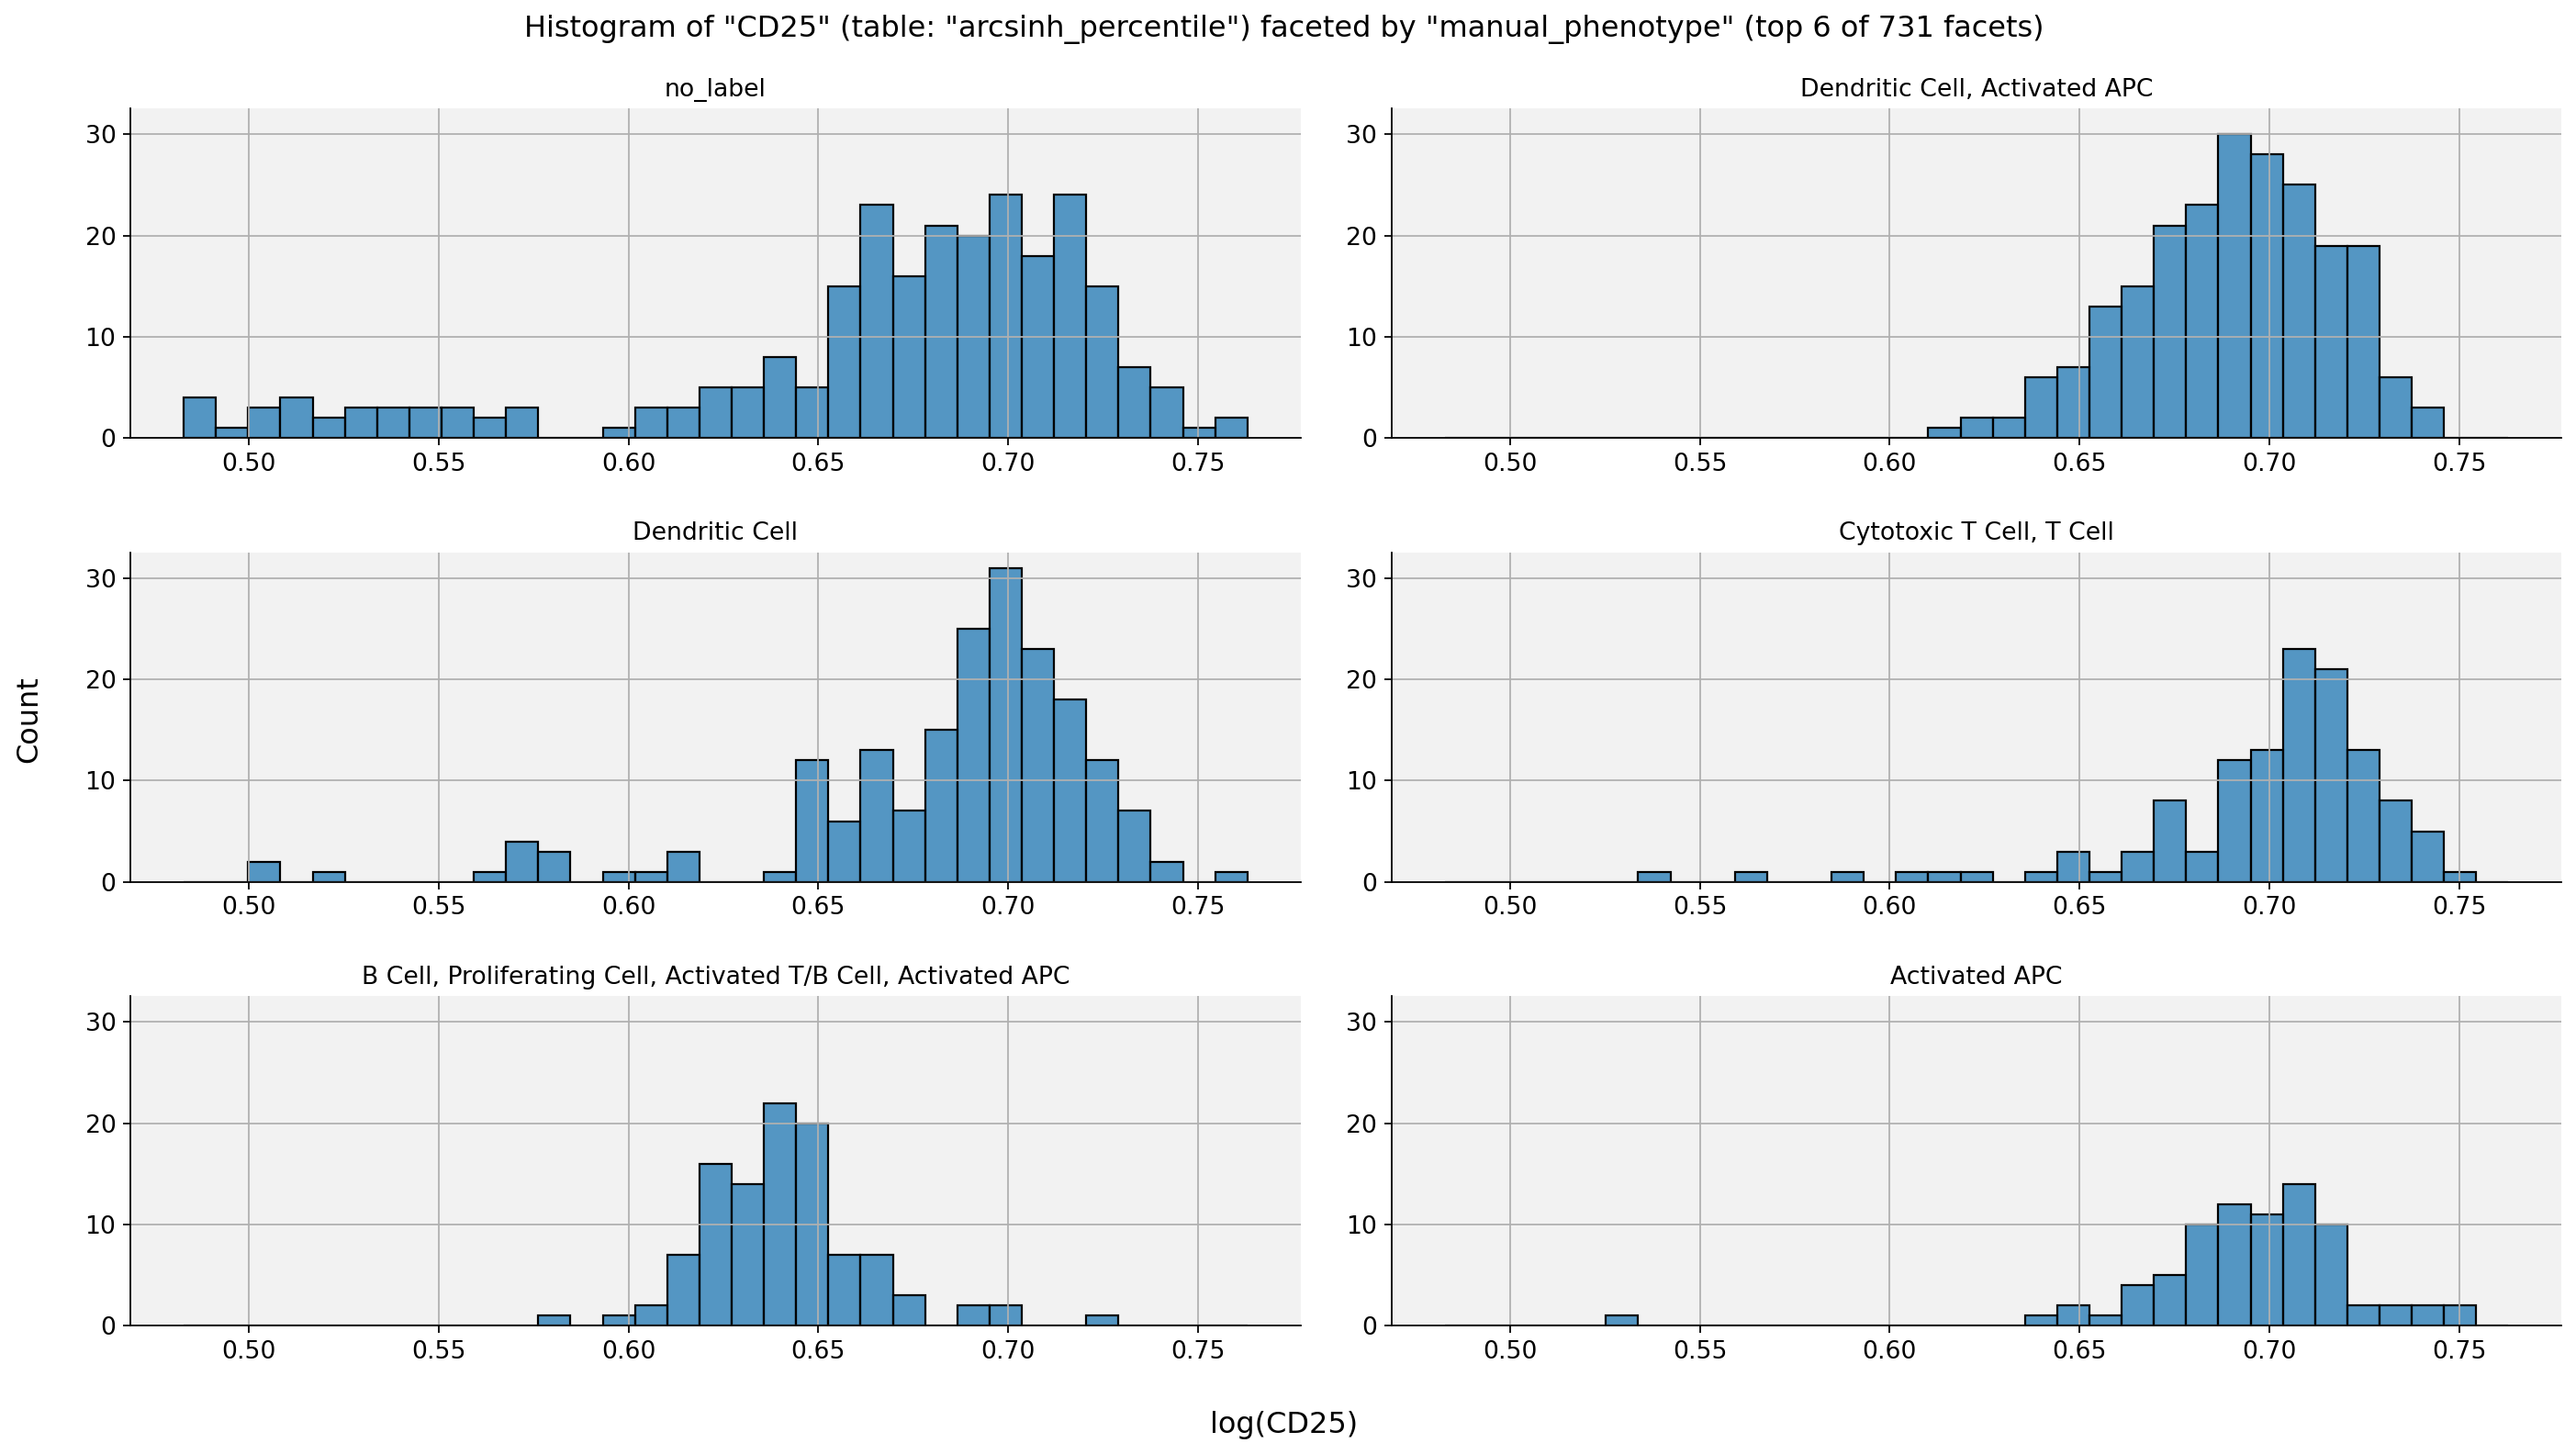

2026-11-08 13:00:44,407 - INFO - Returning figure and dataframe for in-memory use


In [14]:
facet_comparison_params = {
    **params,
    "Group_by": "manual_phenotype",
    "Together": False,
    "Facet": True,
    "Max_Groups": 6,
    "Facet_Ncol": 2,
    "Figure_Width": 18,
    "Figure_Height": 10,
    "Figure_DPI": 160,
    "Font_Size": 12,
}

result = run_from_json(
    json_path=facet_comparison_params,
    save_to_disk=False,
    show_plot=True,
)

# To export the figure at full resolution:
# result[0].savefig("facet-comparison.png", dpi=160, bbox_inches="tight")

## Environment

In [15]:
import os
import socket

print(f"I am running on: {socket.gethostname()}")
print(f"My process ID is: {os.getpid()}")

I am running on: Bojohns-Mac-mini.local
My process ID is: 98964
